# Sensitivität und Robustheit der QA-basierten Faktenretention

## 1. Ziel und Forschungsfrage

Wie empfindlich sind die beobachteten Methodenunterschiede und Rangfolgen gegenüber
**hypothetischen Änderungen vorhandener QA-Urteile**? Untersucht werden das finale
100-Artikel-Hauptexperiment, sechs Verfahren, vier Kompressionsstufen und die vier
bereits definierten Methodenvergleiche.

Die tatsächliche Fehlerrate der QA-Pipeline ist unbekannt. Diese Analyse schätzt sie
**nicht**. Alle Originaldaten und QA-Labels bleiben unverändert. Änderungen werden
ausschließlich in neuen hypothetischen Rechenzuständen vorgenommen. Es gibt keine
LLM-Aufrufe, keine neuen menschlichen Urteile und keine Scorer-Optimierung.

Die Analysen unterscheiden strikt:

- ursprüngliche Ergebnisse und Stichprobenunsicherheit (Artikelbootstrap),
- adversariale minimale Änderungszahlen für einzelne Vergleichsergebnisse,
- Monte-Carlo-Sensitivität bei festgehaltenen 100 Artikeln und angenommenen Änderungsraten,
- eine deterministische permissive Behandlung von `reference_discordant`.

**Wichtig:** Die Lead-k-Werte 1,10 % inkonsistente Faktenverläufe und 95,87 % retained
in einer breiteren Beleggruppe sind keine allgemeine Fehlerrate bzw. unabhängig
gemessener globaler Recall. Aus ihnen werden hier keine Simulationsraten abgeleitet.

## Eingaben, Ausführung und Grenzen

Eingaben: prüfsummengebundene historische Quellen aus `data/eingefrorene_quellen.zip`;
unverändertes Originalnotebook: `data/referenznotebooks.zip::02_QA_Faktenretention_Sensitivitaet.ipynb`.
Ausgaben: `LAUF/workspace/supplement/ergebnisse/02_sensitivitaet/` und die unten im Code bezeichneten Grafikordner.
Lauf mit frischem Kernel: `python 05_analyze.py --only 10_qa_sensitivitaet`.
Abhängigkeiten werden vom Runner zuerst mit eigenen frischen Kerneln ausgeführt:
`03_qa_retention`, `04_laenge_und_adjustierte_retention`.

Für Jupyter: Paket installieren, mit `python 05_analyze.py --prepare --only 10_qa_sensitivitaet --output results/runs/interaktiv`
die Quellen vorbereiten und `FAKTENRETENTION_WORK` auf dieses explizite `workspace` setzen.
Bei abhängigen Notebooks zuerst die genannten Analysen ausführen (siehe `notebooks/README.md`).
Keine Modelle und keine neuen Modellmetriken. Humanratings und Panelmodelle gelten ausschließlich für den historischen Bestand.
Statistische Verfahren, Seeds, Supportfilter und fehlende Werte behalten ihre jeweilige Originaldefinition.


In [1]:
# Explizite Parameter: Pfade aus der Laufkonfiguration, kein vorbereiteter Kernelzustand.
from faktenretention.notebook_context import open_context
context = open_context("10_qa_sensitivitaet")
WORK = context.work
CONTEXT_BASE = WORK / "supplement"
recompute_bootstrap = False  # Historische Regressionscaches sind verpflichtend.


## Einordnung dieses Notebooks

**Warum diese Analyse?** Die zentralen Aussagen der Masterarbeit beruhen auf automatischen Retained-/Nicht-Retained-Urteilen. Deren reale Fehlerquote ist nicht unabhängig vollständig bekannt. Daher wird geprüft, wie stark ausgewählte Verfahrenskontraste auf hypothetische Labeländerungen reagieren.

**Forschungsfrage:** Welche gezielten Änderungsbudgets können Vergleichsvorzeichen umkehren, und wie verhalten sich die Befunde unter festgelegten symmetrischen, asymmetrischen, methodenspezifischen und artikelkorrelierten Szenarien? Simulierte Änderungen sind Annahmen und keine beobachteten Korrekturen oder empirischen Fehlerraten.

**Zusammenhang:** Notebook 01 untersucht interne QA-Plausibilität, Notebook 03 die tatsächliche Wortlänge und Notebook 04 eine zusätzliche LLM-Vergleichsbasis. Die Szenarien dieses Notebooks werden durch die späteren LLM-Urteile nicht rückwirkend zu empirisch validierten Fehlermodellen.

**Mitgelieferte Grundlage:** Alle im ursprünglichen Quellenprotokoll genannten Eingaben liegen unter `daten/hauptexperiment/`. Referenznotebooks werden dort bytegleich als `*.quellnotebook.json` aufbewahrt, weil lediglich ihre gespeicherten Definitionen bzw. Funktionsauszüge gelesen werden. Die vier Arbeitsnotebooks liegen ausschließlich auf oberster Ebene. Ausgaben werden im zugehörigen Unterordner von `ergebnisse/` gespeichert; Originaldateien außerhalb dieses Pakets werden nicht benötigt oder geändert.


### Einrichtung und Konventionen

Python 3.13; NumPy, pandas, Matplotlib und Jupyter. Dieselbe lokale Analyseumgebung
wie beim Lead-k-Notebook kann verwendet werden. Die mitgelieferten Daten liegen unter
`daten/hauptexperiment/`, die Ausgaben unter `ergebnisse/02_sensitivitaet/`.
Die Analyse benötigt keinen Netzwerk- oder Modellzugriff.

Die vier Kontraste sind jeweils **erstes minus zweites Verfahren**. Positive
Differenzen begünstigen das erste Verfahren. Prozentpunkte (pp) und Prozentanteile
werden getrennt beschriftet. Originaldatenstand: `aktuell_20260930`.

In [2]:
from pathlib import Path
from fractions import Fraction
from collections import Counter, defaultdict
from itertools import combinations
import ast, gzip, hashlib, html, importlib.metadata, json, math, os, platform, re, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, MaxNLocator
from IPython.display import display, Markdown, HTML

sys.dont_write_bytecode = True
BUNDLE = next((p for p in [CONTEXT_BASE, *CONTEXT_BASE.parents] if (p/'daten/paket_manifest.json').is_file()), None)
assert BUNDLE is not None, 'Notebook aus dem entpackten Analysepaket starten.'
PACKAGE = WORK/'project'
ROOT = BUNDLE/'ergebnisse/02_sensitivitaet'
assert ROOT != PACKAGE and PACKAGE not in ROOT.parents, 'Ausgaben außerhalb des Quellpakets speichern.'
DATA = PACKAGE/'02_Auswertung/hauptexperiment_qa_daten'
ORIGINAL = PACKAGE/'02_Auswertung/hauptexperiment_qa_ergebnisse/aktuell_20260930'
LENGTH = PACKAGE/'02_Auswertung/hauptexperiment_laengen_ergebnisse/aktuell_20260930'
OUT = ROOT
FIG = OUT/'abbildungen'
FIG.mkdir(parents=True,exist_ok=True)
VERSION = 'aktuell_20260930'
METHODS = ['lead_k','plain','zero_shot_cot','few_shot_cot','auto_cot','automate_cot']
NAMES = dict(zip(METHODS,['Lead-k','Plain','Zero-Shot-CoT','Few-Shot-CoT','Auto-CoT','Automate-CoT']))
STAGES = [500,300,150,75]
CONTRASTS = [('zero_shot_cot','plain'),('few_shot_cot','plain'),
             ('auto_cot','few_shot_cot'),('automate_cot','auto_cot')]
KEY = ['article_id','method','stage_target_words','canonical_fact_id']
CELL = ['article_id','method','stage_target_words']
SEED, B = 32, 10_000
SIM_SEED, REPEATS, BATCH = 32026, 5_000, 500
RATES = [.005,.01,.02,.03,.05,.10]
pd.set_option('display.max_rows',28)
pd.set_option('display.max_columns',16)
plt.rcParams.update({'figure.dpi':110,'savefig.dpi':200,'font.size':11,
                     'axes.spines.top':False,'axes.spines.right':False})
STAGE_COLORS = {500:'#0072B2',300:'#D55E00',150:'#009E73',75:'#CC79A7'}

def export(frame,name):
    frame.to_csv(OUT/f'{name}.csv',index=False,encoding='utf-8-sig')

def savefig(fig,name):
    for extension in ['png','svg','pdf']:
        fig.savefig(FIG/f'{name}.{extension}',bbox_inches='tight')
    plt.show()
    plt.close(fig)

def pct(n,d): return 100*n/d if d else np.nan
def de(x,digits=2): return f'{x:.{digits}f}'.replace('.',',') if pd.notna(x) else 'nicht bestimmbar'
def sha(path): return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def read(path,strings=False):
    frame = pd.read_csv(path,keep_default_na=False,**({'dtype':str} if strings else {}))
    for column in ['article_id','stage_target_words']:
        if column in frame: frame[column] = frame[column].astype(int)
    return frame

software = {'python':platform.python_version(),**{m:importlib.metadata.version(m)
            for m in ['numpy','pandas','matplotlib','nbformat','nbclient','nbconvert','ipykernel']}}
display(pd.Series(software,name='Version').to_frame())

,Version
python,3.13.15
numpy,2.5.4
pandas,3.0.6
matplotlib,3.11.2
nbformat,5.11.1
nbclient,0.11.0
nbconvert,7.17.2
ipykernel,7.4.0


## 2. Datenüberprüfung und Reproduktion

### Quellen und unveränderte Labels

Aus `scored_archived.csv.gz` werden die bereits gespeicherten finalen Bewertungsfelder
übernommen. `lost` und `reference_discordant` ergeben binär 0, `retained` ergibt 1.
Technische Fehlwerte bleiben fehlend. Der vollständige finale Scorer ist als Quelle
dokumentiert, wird hier aber nicht zur Neuklassifikation aufgerufen.

Vor den Sensitivitätsanalysen müssen die 2.400 Artikel-Methoden-Stufen-Werte, die
24 Retentionsmittelwerte, alle 16 vordefinierten gepaarten Differenzen und deren
95-%-Bootstrap-Intervalle mit den vorhandenen Analysen übereinstimmen. Bei einer
Abweichung wird ein Abgleich exportiert und die Analyse gestoppt.

In [3]:
manifest = json.loads((DATA/'source_manifest.json').read_text())
assert manifest['default_version']==VERSION
manifest_entries = {x['file']:x for x in manifest['files']}
source_paths = [DATA/'source_manifest.json']
relative_inputs = ['shared/canonical_facts.csv.gz', f'{VERSION}/summaries.csv.gz',
                   f'{VERSION}/answers.csv.gz', f'{VERSION}/scored_archived.csv.gz',
                   'code/qa_scorer_snapshot.py','code/score_model_selection_batch.py']
for relative in relative_inputs:
    path = DATA/relative
    assert sha(path)==manifest_entries[relative]['sha256'],path
    if path.suffix=='.gz':
        assert hashlib.sha256(gzip.decompress(path.read_bytes())).hexdigest()==manifest_entries[relative]['original_sha256']
    source_paths.append(path)
source_paths += [ORIGINAL/name for name in ['retention_artikelebene.csv','retention_mittelwerte_95ci.csv',
    'vier_gepaarte_kontraste_pp_95ci.csv','qa_labels_reproduziert.csv.gz']]
source_paths += [LENGTH/name for name in ['artikelwerte_laenge_retention.csv',
    'retention_und_drei_rangfolgen_24_gruppen.csv','vollstaendige_24_gruppen_main_100.csv']]
source_paths += [PACKAGE/'02_Auswertung/hauptexperiment_01_qa_faktenretention.quellnotebook.json',
    PACKAGE/'02_Auswertung/hauptexperiment_02_laengeneinhaltung.quellnotebook.json',
    PACKAGE/'03_Experiment/compute_length_adjusted_retention.py',
    PACKAGE/'03_Experiment/iterative_summarize.py',PACKAGE/'README_START.md']
sources_before = {str(p):sha(p) for p in source_paths}
sources = pd.DataFrame([{'Datei':str(p.relative_to(PACKAGE)),'sha256':sources_before[str(p)]}
                        for p in source_paths])
export(sources,'quellen_sha256')
display(sources[['Datei']])

facts = read(DATA/'shared/canonical_facts.csv.gz',strings=True)
summaries = read(DATA/VERSION/'summaries.csv.gz',strings=True)
qa = read(DATA/VERSION/'scored_archived.csv.gz',strings=True).rename(columns={'summary_prompt_variant':'method'})
raw = read(DATA/VERSION/'answers.csv.gz',strings=True).rename(columns={'summary_prompt_variant':'method'})
assert len(facts)==2000 and facts.canonical_fact_id.is_unique
assert facts.groupby('article_id').size().eq(20).all()
IDS = sorted(facts.article_id.unique().tolist())
assert len(IDS)==100 and len(summaries)==600
assert not summaries.duplicated(['article_id','method']).any()
assert len(qa)==len(raw)==48000 and not qa.duplicated(KEY).any()
expected = {(a,m,t,f) for a,fs in facts.groupby('article_id') for f in fs.canonical_fact_id
            for m in METHODS for t in STAGES}
assert set(qa[KEY].itertuples(index=False,name=None))==expected
assert set(raw[KEY].itertuples(index=False,name=None))==expected
joined = qa.merge(raw,on=KEY,suffixes=('_arch','_raw'),validate='one_to_one')
for field in ['question','reference_answer','answer','support','error','answer_status']:
    assert joined[field+'_arch'].eq(joined[field+'_raw']).all(),field
fact_join = qa.merge(facts[['article_id','canonical_fact_id','question','reference_answer']],
    on=['article_id','canonical_fact_id'],validate='many_to_one',suffixes=('','_fact'))
assert fact_join.question.eq(fact_join.question_fact).all()
assert fact_join.reference_answer.eq(fact_join.reference_answer_fact).all()
qa['label'] = np.select([qa.technical_missing.eq('True'),qa.retention.eq('True'),
    qa.loss.eq('True'),qa.reference_discordant_answer.eq('True')],
    ['technical_missing','retained','lost','reference_discordant'],default='INVALID')
assert not qa.label.eq('INVALID').any()
qa['valid'] = qa.label.ne('technical_missing')
qa['retained_binary'] = qa.label.eq('retained').astype(int)
assert (~qa.valid).sum()==196
assert qa.valid.eq(qa.analysis_eligible.eq('True')).all()
assert (~qa.valid).eq(qa.error.ne('')).all()
stored_labels = read(ORIGINAL/'qa_labels_reproduziert.csv.gz',strings=True)
label_check = qa[KEY+['label']].merge(stored_labels[KEY+['label']],on=KEY,
    validate='one_to_one',suffixes=('','_existing'))
assert label_check.label.eq(label_check.label_existing).all()
original_label_digest = hashlib.sha256(qa[KEY+['label']].to_csv(index=False).encode()).hexdigest()

article = qa.groupby(CELL).agg(n_total=('valid','size'),n_valid=('valid','sum'),
    n_retained=('retained_binary','sum'),n_missing=('technical_missing',lambda s:s.eq('True').sum()),
    n_discordant=('label',lambda s:s.eq('reference_discordant').sum())).reset_index()
assert len(article)==2400 and article.n_total.eq(20).all() and article.n_valid.gt(0).all()
article['retention_observed'] = article.n_retained/article.n_valid
article['retention_lower'] = article.n_retained/20
reference_article = read(ORIGINAL/'retention_artikelebene.csv')
check = article.merge(reference_article,on=CELL,validate='one_to_one',suffixes=('','_archive'))
for field in ['n_retained','n_valid','n_missing','retention_observed','retention_lower']:
    assert np.allclose(check[field],check[field+'_archive'],rtol=0,atol=1e-12),field
coverage = pd.DataFrame({'Einheit':['Artikel','Fakten','Zusammenfassungen','QA-Positionen','Gültige QA-Urteile','Technische Fehlwerte'],
    'Anzahl':[len(IDS),len(facts),len(summaries)*4,len(qa),int(qa.valid.sum()),int((~qa.valid).sum())]})
display(coverage)
export(coverage,'eingabeabdeckung')

,Datei
0,02_Auswertung/hauptexperiment_qa_daten/source_...
1,02_Auswertung/hauptexperiment_qa_daten/shared/...
2,02_Auswertung/hauptexperiment_qa_daten/aktuell...
3,02_Auswertung/hauptexperiment_qa_daten/aktuell...
4,02_Auswertung/hauptexperiment_qa_daten/aktuell...
5,02_Auswertung/hauptexperiment_qa_daten/code/qa...
6,02_Auswertung/hauptexperiment_qa_daten/code/sc...
7,02_Auswertung/hauptexperiment_qa_ergebnisse/ak...
8,02_Auswertung/hauptexperiment_qa_ergebnisse/ak...
9,02_Auswertung/hauptexperiment_qa_ergebnisse/ak...


,Einheit,Anzahl
0,Artikel,100
1,Fakten,2000
2,Zusammenfassungen,2400
3,QA-Positionen,48000
4,Gültige QA-Urteile,47804
5,Technische Fehlwerte,196


### Hauptmetrik und wiederverwendete Statistikfunktionen

Für Artikel \(i\), Verfahren \(m\), Stufe \(t\):
\(R_{imt}=K_{imt}/V_{imt}\), mit retained-Zähler \(K\) und gültigem QA-Nenner \(V\).
Der Methodenmittelwert ist der gleichgewichtete Mittelwert der 100 Artikelquoten.
Die gepaarte Differenz lautet \(100\,\overline{R_A-R_B}\) in Prozentpunkten.

Die Funktionen `estimate`, `means_for` und `contrasts_for` werden unverändert als
AST-begrenzte Funktionsauszüge aus dem bestehenden Notebook geladen. Kein übriger
Notebookcode wird ausgeführt. `estimate` sortiert numerische Artikel-IDs und verwendet
10.000 Artikelbootstrap-Ziehungen mit Seed 32. Diese Intervalle beschreiben allein
Stichprobenvariation bei fixierten Labels.

In [4]:
from faktenretention.statistics import estimate, means_for, contrasts_for

original_means = means_for(article)
original_contrasts = contrasts_for(article)
mean_reference = read(ORIGINAL/'retention_mittelwerte_95ci.csv')
contrast_reference = read(ORIGINAL/'vier_gepaarte_kontraste_pp_95ci.csv')
checks = []
for title,new,old,keys in [
    ('24 Mittelwerte und Intervalle',original_means,mean_reference,['method','stage_target_words']),
    ('16 gepaarte Differenzen und Intervalle',original_contrasts,contrast_reference,['first','second','stage_target_words'])]:
    paired = new.merge(old,on=keys,validate='one_to_one',suffixes=('_new','_reference'))
    for field in ['n_articles','mean','ci_low','ci_high']:
        delta = np.abs(paired[field+'_new']-paired[field+'_reference'])
        checks.append({'Abgleich':title,'Feld':field,'max_abs_Abweichung':float(delta.max()),
                       'bestanden':bool(delta.le(1e-12).all())})
reproduction = pd.DataFrame(checks)
export(reproduction,'reproduktion_originalmittelwerte_und_kontraste')
display(reproduction)
assert reproduction.bestanden.all(), 'Originalwerte weichen ab: vor Sensitivitätsanalyse klären.'
export(original_means,'original_retention_mittelwerte_95ci')
export(original_contrasts,'original_vier_kontraste_pp_95ci')
display(original_contrasts[['contrast','stage_target_words','mean','ci_low','ci_high']].round(3))

,Abgleich,Feld,max_abs_Abweichung,bestanden
0,24 Mittelwerte und Intervalle,n_articles,0.000000e+00,True
1,24 Mittelwerte und Intervalle,mean,5.551115e-17,True
2,24 Mittelwerte und Intervalle,ci_low,8.326673e-17,True
3,24 Mittelwerte und Intervalle,ci_high,5.551115e-17,True
4,16 gepaarte Differenzen und Intervalle,n_articles,0.000000e+00,True
5,16 gepaarte Differenzen und Intervalle,mean,1.776357e-15,True
6,16 gepaarte Differenzen und Intervalle,ci_low,1.776357e-15,True
7,16 gepaarte Differenzen und Intervalle,ci_high,1.776357e-15,True


,contrast,stage_target_words,mean,ci_low,ci_high
0,Zero-Shot-CoT − Plain,500,16.997,14.294,19.768
1,Zero-Shot-CoT − Plain,300,17.843,15.113,20.575
2,Zero-Shot-CoT − Plain,150,8.523,5.587,11.325
3,Zero-Shot-CoT − Plain,75,-4.874,-7.574,-2.247
4,Few-Shot-CoT − Plain,500,9.299,6.754,11.883
5,Few-Shot-CoT − Plain,300,11.032,8.513,13.572
6,Few-Shot-CoT − Plain,150,5.719,3.275,8.147
7,Few-Shot-CoT − Plain,75,0.750,-1.676,3.170
8,Auto-CoT − Few-Shot-CoT,500,7.146,4.894,9.481
9,Auto-CoT − Few-Shot-CoT,300,7.119,4.980,9.318


### Längenadjustierte Kennzahl und Originalrangfolgen

Die unveränderte sekundäre Metrik lautet
\(R^{adj}_{imt}=(K_{imt}/20)/(1+D_{imt})\).
Dabei ist \(D\) der Abstand zum zulässigen ±5-%-Wortfenster, dividiert durch die
Zielwortzahl. Diese Metrik verwendet bereits im Projekt den **festen Nenner 20**;
dies wird nicht an den gültigen Nenner der Hauptmetrik angeglichen. Technische
Fehlwerte werden auch hier nie simuliert oder umklassifiziert; der feste Nenner ist
lediglich die unveränderte Berechnungsdefinition der sekundären Kennzahl.

Wortzählung und Fenstergrenzen werden aus unveränderten Originalfunktionen geladen,
die tatsächlichen Summaries nachgezählt und die gespeicherten Längenstrafen geprüft.
Ränge sind Wettbewerbsränge (1, 2, 2, 4). Gleichstände werden nicht nach Methodennamen
aufgelöst. Die Originalrangfolgen werden zusätzlich gegen exakte Projektwerte geprüft.

In [5]:
from faktenretention.text_rules import count_words, bounds_for_target
length_ns={'count_words':count_words,'bounds_for_target':bounds_for_target}

length_rows=[]
for row in summaries.itertuples():
    for stage in STAGES:
        text=getattr(row,f'summary_{stage}')
        words=length_ns['count_words'](text)
        low,high=length_ns['bounds_for_target'](stage,5.0)
        assert words==int(getattr(row,f'summary_{stage}_word_count'))
        violation=max(low-words,words-high,0)
        length_rows.append(dict(article_id=row.article_id,method=row.method,stage_target_words=stage,
            W=words,violation_words=violation,D=violation/stage,
            summary_sha256=hashlib.sha256(text.encode()).hexdigest()))
length_values=pd.DataFrame(length_rows)
length_archive=read(LENGTH/'artikelwerte_laenge_retention.csv')
cross=length_values.merge(length_archive,on=CELL,validate='one_to_one',suffixes=('','_old'))
for name in ['W','violation_words','D']:
    assert np.allclose(cross[name],cross[name+'_old'],rtol=0,atol=1e-12),name
assert cross.summary_sha256.eq(cross.summary_sha256_old).all()
article=article.merge(length_values,on=CELL,validate='one_to_one')
article['R_adj']=article.retention_lower/(1+article.D)
reference_groups=read(LENGTH/'vollstaendige_24_gruppen_main_100.csv')
length_reproduction=[]
for row in reference_groups.itertuples():
    sub=article[article.method.eq(row.method)&article.stage_target_words.eq(row.stage_target_words)]
    stats=estimate(sub.set_index('article_id').R_adj)
    for name in ['mean','ci_low','ci_high']:
        delta=abs(stats[name]-getattr(row,'R_adj_'+name))
        length_reproduction.append(dict(method=row.method,stage_target_words=row.stage_target_words,
            field=name,abs_difference=delta,passed=delta<=1e-12))
length_reproduction=pd.DataFrame(length_reproduction)
export(length_reproduction,'reproduktion_laengenadjustiert')
assert length_reproduction.passed.all()

def rank_scores(scores,tol=0.0):
    # Letzte Achse = Verfahren. Gleichstand erhält denselben Wettbewerbsrang.
    return 1+np.sum(scores[...,None,:] > scores[...,:,None]+tol,axis=-1)

def tensor(column,dtype=float):
    index=pd.MultiIndex.from_product([IDS,METHODS,STAGES],names=CELL)
    return article.set_index(CELL)[column].reindex(index).to_numpy(dtype=dtype).reshape(len(IDS),6,4)

V=tensor('n_valid',int)
K=tensor('n_retained',int)
DISCORD=tensor('n_discordant',int)
PENALTY=1/(1+tensor('D'))
ORIG_RAW=(K/V).mean(axis=0)
ORIG_ADJ=(K/20*PENALTY).mean(axis=0)
LCM=math.lcm(*np.unique(V).tolist())
assert LCM*100*20 < np.iinfo(np.int64).max
RAW_SCALE=LCM//V
ORIG_RAW_SCORES=(K*RAW_SCALE).sum(axis=0)
assert np.allclose(ORIG_RAW,ORIG_RAW_SCORES/(LCM*len(IDS)))
original_ranks_raw=rank_scores(ORIG_RAW_SCORES.T).T
original_ranks_adj=rank_scores(ORIG_ADJ.T,tol=1e-12).T
rank_rows=[]
for mi,method in enumerate(METHODS):
    for ti,stage in enumerate(STAGES):
        row=reference_groups[reference_groups.method.eq(method)&reference_groups.stage_target_words.eq(stage)].iloc[0]
        assert original_ranks_raw[mi,ti]==row.rank_R_obs
        assert original_ranks_adj[mi,ti]==row.rank_R_adj
        rank_rows.append(dict(method=method,stage_target_words=stage,
            raw_percent=100*ORIG_RAW[mi,ti],adjusted_percent=100*ORIG_ADJ[mi,ti],
            original_rank_raw=int(original_ranks_raw[mi,ti]),original_rank_adjusted=int(original_ranks_adj[mi,ti])))
original_ranks=pd.DataFrame(rank_rows)
export(original_ranks,'original_mittelwerte_und_rangfolgen')
display(original_ranks.round(3))
display(Markdown('**Reproduktion bestanden:** alle 24 Hauptmittelwerte, 16 gepaarten Kontraste, '
    'zugehörigen Originalintervalle sowie 24 adjustierten Mittelwerte und Intervalle '
    'stimmen innerhalb 10⁻¹² mit dem vorhandenen Projekt überein. Auch beide Originalrangfolgen stimmen.'))

,method,stage_target_words,raw_percent,adjusted_percent,original_rank_raw,original_rank_adjusted
0,lead_k,500,75.587,75.400,1,1
1,lead_k,300,49.368,49.300,6,5
2,lead_k,150,30.242,30.200,6,6
3,lead_k,75,17.308,17.300,6,6
4,plain,500,54.892,36.154,6,6
5,plain,300,50.011,37.291,5,6
6,plain,150,45.108,40.604,5,5
7,plain,75,33.800,24.724,4,5
8,zero_shot_cot,500,71.888,57.468,3,3
9,zero_shot_cot,300,67.854,63.623,3,2


**Reproduktion bestanden:** alle 24 Hauptmittelwerte, 16 gepaarten Kontraste, zugehörigen Originalintervalle sowie 24 adjustierten Mittelwerte und Intervalle stimmen innerhalb 10⁻¹² mit dem vorhandenen Projekt überein. Auch beide Originalrangfolgen stimmen.

## 3. Analyse A: minimal notwendige Labeländerungen

### Exakter adversarialer Worst-Case-Test

Jeder Vergleich und jede Stufe wird **isoliert** angegriffen; die Lösungen sind keine
gemeinsame konsistente Änderung aller 16 Kontraste und werden nicht addiert.
Technische Fehlwerte und die Artikelnenner bleiben fest. Verändert wird ausschließlich
der temporäre Binärwert eines gültigen Urteils.

Für eine positive Ausgangsdifferenz sind schädliche Änderungen `retained → 0` bei A
oder `not_retained → 1` bei B; bei negativer Differenz umgekehrt. Eine solche Änderung
verschiebt die Differenz um \(100/(100 V_{im})=1/V_{im}\) Prozentpunkte. Wegen der
tatsächlichen Nenner 17–20 sind die Gewichte nicht durchgehend identisch.

**Begründung der Minimalität:** Sortiert man alle zulässigen schädlichen Änderungen
absteigend nach ihrem Gewicht, maximiert jede Präfixlänge k die erreichbare Verschiebung
bei k Änderungen. Das kleinste k mit kumulierter Verschiebung ≥ Betrag der Originaldifferenz
ist deshalb exakt minimal zum Erreichen **oder Überschreiten** von null. Zusätzlich
wird das kleinste k für eine **strikte** Vorzeichenumkehr berechnet. Exakter Gleichstand
wird separat kenntlich gemacht; ein Überschreiten wird nicht als Gleichstand bezeichnet.
Alle Schwellwertprüfungen verwenden `Fraction`, keine gerundeten Differenzen.

Auswahlregel: zuerst höchstes Gewicht, dann Artikel-ID, Methodenreihenfolge und Fakten-ID.
Zusätzlich werden zwei gleich minimale Lösungen mit **demselben optimalen Gewichtsmultiset**
konstruiert: eine konzentriert Änderungen auf wenige Artikel, eine verteilt sie breit.
Die resultierende Spannweite ist eine tatsächlich gefundene Alternative, kein Beweis
global minimaler/maximaler Artikelzahlen unter sämtlichen denkbaren Lösungen.

In [6]:
qa_candidates=qa.merge(article[CELL+['n_valid']],on=CELL,validate='many_to_one').copy()
qa_candidates['method_order']=qa_candidates.method.map(dict(zip(METHODS,range(6))))
article_lookup=article.set_index(CELL)

def exact_difference(first,second,stage):
    total=Fraction(0)
    for a in IDS:
        left=article_lookup.loc[(a,first,stage)]
        right=article_lookup.loc[(a,second,stage)]
        total+=Fraction(int(left.n_retained),int(left.n_valid))-Fraction(int(right.n_retained),int(right.n_valid))
    return total*Fraction(100,len(IDS))

def threshold_count(weights,gap,strict=False):
    cumulative=Fraction(0)
    for i,w in enumerate(weights,1):
        cumulative+=w
        if cumulative>gap if strict else cumulative>=gap:
            return i
    return None

def tied_solution(ordered,k,strategy):
    # Nur die Reihenfolge innerhalb exakt gleich gewichteter Tiers ändert sich.
    selected=[]
    use=Counter()
    remaining=k
    for denominator,tier in ordered.groupby('n_valid',sort=True):
        take=min(remaining,len(tier))
        if take==0: break
        if strategy=='canonical':
            chosen=tier.head(take).index.tolist()
        else:
            groups={a:g.index.tolist() for a,g in tier.groupby('article_id',sort=True)}
            chosen=[]
            for _ in range(take):
                available=[a for a,indices in groups.items() if indices]
                if strategy=='compact':
                    a=min(available,key=lambda a:(not bool(use[a]),-len(groups[a]),a))
                else:
                    a=min(available,key=lambda a:(use[a],a))
                chosen.append(groups[a].pop(0))
                use[a]+=1
        selected.extend(chosen)
        if strategy=='canonical': use.update(ordered.loc[chosen,'article_id'])
        remaining-=take
    assert remaining==0
    return ordered.loc[selected].copy()

attack_rows=[]
attack_plans=[]
budget_rows=[]

In [7]:
for first,second in CONTRASTS:
    for stage in STAGES:
        diff=exact_difference(first,second,stage)
        assert diff!=0, 'Für Originalgleichstand muss die Zieldefinition separat festgelegt werden.'
        sign=1 if diff>0 else -1
        pool=qa_candidates[qa_candidates.method.isin([first,second]) &
             qa_candidates.stage_target_words.eq(stage) & qa_candidates.valid].copy()
        pool['hypothetical_binary']=np.where(pool.method.eq(first),0 if sign>0 else 1,1 if sign>0 else 0)
        pool=pool[pool.retained_binary.ne(pool.hypothetical_binary)].copy()
        pool=pool.sort_values(['n_valid','article_id','method_order','canonical_fact_id'])
        weights=[Fraction(100,len(IDS)*int(v)) for v in pool.n_valid]
        gap=abs(diff)
        k_nonpositive=threshold_count(weights,gap)
        k_reverse=threshold_count(weights,gap,strict=True)
        assert k_nonpositive is not None and k_reverse is not None
        assert sum(weights[:k_nonpositive],Fraction(0))>=gap
        assert sum(weights[:max(0,k_nonpositive-1)],Fraction(0))<gap
        assert sum(weights[:k_reverse],Fraction(0))>gap
        assert sum(weights[:max(0,k_reverse-1)],Fraction(0))<=gap
        denominator=int(article[article.method.isin([first,second])&article.stage_target_words.eq(stage)].n_valid.sum())
        article_counts=[]
        combined=None
        for strategy in ['canonical','compact','spread']:
            solution=tied_solution(pool,k_reverse,strategy)
            impact=sum((Fraction(100,len(IDS)*int(v)) for v in solution.n_valid),Fraction(0))
            after=diff-sign*impact
            assert after*diff<0
            # Lösung auf separater Kopie der Artikelzähler anwenden und exakt nachrechnen.
            deltas=solution.assign(change=solution.hypothetical_binary-solution.retained_binary).groupby(['article_id','method']).change.sum()
            after_direct=Fraction(0)
            for a in IDS:
                l=article_lookup.loc[(a,first,stage)]
                r=article_lookup.loc[(a,second,stage)]
                kl=int(l.n_retained)+int(deltas.get((a,first),0))
                kr=int(r.n_retained)+int(deltas.get((a,second),0))
                assert 0<=kl<=l.n_valid and 0<=kr<=r.n_valid
                after_direct+=Fraction(kl,int(l.n_valid))-Fraction(kr,int(r.n_valid))
            assert after_direct*Fraction(100,len(IDS))==after
            article_counts.append(solution.article_id.nunique())
            plan=solution[KEY+['label','retained_binary','hypothetical_binary','n_valid','question','reference_answer']].copy()
            plan['contrast_first']=first; plan['contrast_second']=second; plan['strategy']=strategy
            plan['change_number']=np.arange(1,len(plan)+1)
            plan['effect_pp']=100/(len(IDS)*plan.n_valid)
            plan['original_difference_pp']=float(diff)
            attack_plans.append(plan)
            if strategy=='canonical':
                combined=solution
                canonical_after=after
        first_weights=[Fraction(100,len(IDS)*int(v)) for v in pool.loc[pool.method.eq(first),'n_valid']]
        second_weights=[Fraction(100,len(IDS)*int(v)) for v in pool.loc[pool.method.eq(second),'n_valid']]
        attack_rows.append(dict(first=first,second=second,contrast=f'{NAMES[first]} − {NAMES[second]}',
            stage_target_words=stage,original_difference_pp=float(diff),original_difference_exact=str(diff),
            min_tie_or_cross=k_nonpositive,min_strict_reverse=k_reverse,
            exact_tie_in_optimal_prefix=sum(weights[:k_nonpositive],Fraction(0))==gap,
            difference_after_min_tie_or_cross_pp=float(diff-sign*sum(weights[:k_nonpositive],Fraction(0))),
            difference_after_strict_reverse_pp=float(canonical_after),
            valid_comparison_judgments=denominator,min_reverse_percent_valid=pct(k_reverse,denominator),
            n_changes_first=int(combined.method.eq(first).sum()),n_changes_second=int(combined.method.eq(second).sum()),
            n_articles_canonical=article_counts[0],n_articles_compact=article_counts[1],n_articles_spread=article_counts[2],
            n_articles_min_found=min(article_counts),n_articles_max_found=max(article_counts),
            min_reverse_only_first=threshold_count(first_weights,gap,strict=True),
            min_reverse_only_second=threshold_count(second_weights,gap,strict=True)))
        for budget in [10,20,50,100]:
            actual=min(budget,len(weights))
            impact=sum(weights[:actual],Fraction(0))
            budget_rows.append(dict(first=first,second=second,stage_target_words=stage,budget=budget,
                used_changes=actual,removed_gap_pp=float(impact),
                original_gap_closed_percent=min(100,float(100*impact/gap)),
                difference_after_pp=float(diff-sign*impact),strict_reverse=impact>gap))
attacks=pd.DataFrame(attack_rows)
plans=pd.concat(attack_plans,ignore_index=True)
budgets=pd.DataFrame(budget_rows)
export(attacks,'A_minimale_adversariale_aenderungen')
export(plans,'A_konkrete_hypothetische_aenderungsplaene')
export(budgets,'A_wirkung_erster_10_20_50_100_aenderungen')

In [8]:
display(attacks[['contrast','stage_target_words','original_difference_pp','min_tie_or_cross','min_strict_reverse',
    'min_reverse_percent_valid','n_changes_first','n_changes_second','n_articles_compact','n_articles_spread']].round(3))
display(Markdown('**Nenner:** jeweils alle gültigen QA-Urteile beider Verfahren auf der betreffenden Stufe. '
    'Prozentanteile sind Worst-Case-Änderungsbudgets, keine geschätzten Fehlerraten. '
    'Die vier Budgetauswertungen deckeln den aufgehobenen Anteil der ursprünglichen Differenz bei 100 %; '
    'die zusätzliche Spalte `difference_after_pp` zeigt ein etwaiges Überschreiten.'))
widest=attacks.assign(article_span=attacks.n_articles_max_found-attacks.n_articles_min_found).sort_values('article_span',ascending=False).iloc[0]
display(Markdown(f'**Alternative gleich minimale Lösungen:** Für {widest.contrast} bei '
    f'{int(widest.stage_target_words)} Wörtern betreffen die {int(widest.min_strict_reverse)} Änderungen '
    f'je nach Gleichstandsauswahl {int(widest.n_articles_min_found)} bis {int(widest.n_articles_max_found)} Artikel. '
    'Diese gefundenen Beispiele zeigen, dass die minimale Urteilszahl allein keine eindeutige Zahl '
    'betroffener Artikel festlegt.'))

,contrast,stage_target_words,original_difference_pp,min_tie_or_cross,min_strict_reverse,min_reverse_percent_valid,n_changes_first,n_changes_second,n_articles_compact,n_articles_spread
0,Zero-Shot-CoT − Plain,500,16.997,331,332,8.335,178,154,14,100
1,Zero-Shot-CoT − Plain,300,17.843,347,348,8.739,172,176,16,100
2,Zero-Shot-CoT − Plain,150,8.523,162,163,4.091,40,123,13,53
3,Zero-Shot-CoT − Plain,75,-4.874,94,95,2.380,60,35,5,45
4,Few-Shot-CoT − Plain,500,9.299,175,175,4.404,113,62,14,19
5,Few-Shot-CoT − Plain,300,11.032,211,212,5.323,91,121,14,55
6,Few-Shot-CoT − Plain,150,5.719,105,106,2.668,63,43,8,19
7,Few-Shot-CoT − Plain,75,0.750,14,14,0.351,6,8,2,3
8,Auto-CoT − Few-Shot-CoT,500,7.146,134,134,3.374,84,50,9,19
9,Auto-CoT − Few-Shot-CoT,300,7.119,134,134,3.365,112,22,13,15


**Nenner:** jeweils alle gültigen QA-Urteile beider Verfahren auf der betreffenden Stufe. Prozentanteile sind Worst-Case-Änderungsbudgets, keine geschätzten Fehlerraten. Die vier Budgetauswertungen deckeln den aufgehobenen Anteil der ursprünglichen Differenz bei 100 %; die zusätzliche Spalte `difference_after_pp` zeigt ein etwaiges Überschreiten.

**Alternative gleich minimale Lösungen:** Für Zero-Shot-CoT − Plain bei 500 Wörtern betreffen die 332 Änderungen je nach Gleichstandsauswahl 14 bis 100 Artikel. Diese gefundenen Beispiele zeigen, dass die minimale Urteilszahl allein keine eindeutige Zahl betroffener Artikel festlegt.

### Abbildung 1: Robustheit der Methodenvergleiche

Originaldifferenzen mit den reproduzierten Artikelbootstrap-Intervallen stehen neben
den minimalen gezielten Änderungen für eine **strikte** Umkehr des Punktschätzers.
Das Angreifen des Konfidenzintervalls wäre eine andere Fragestellung.

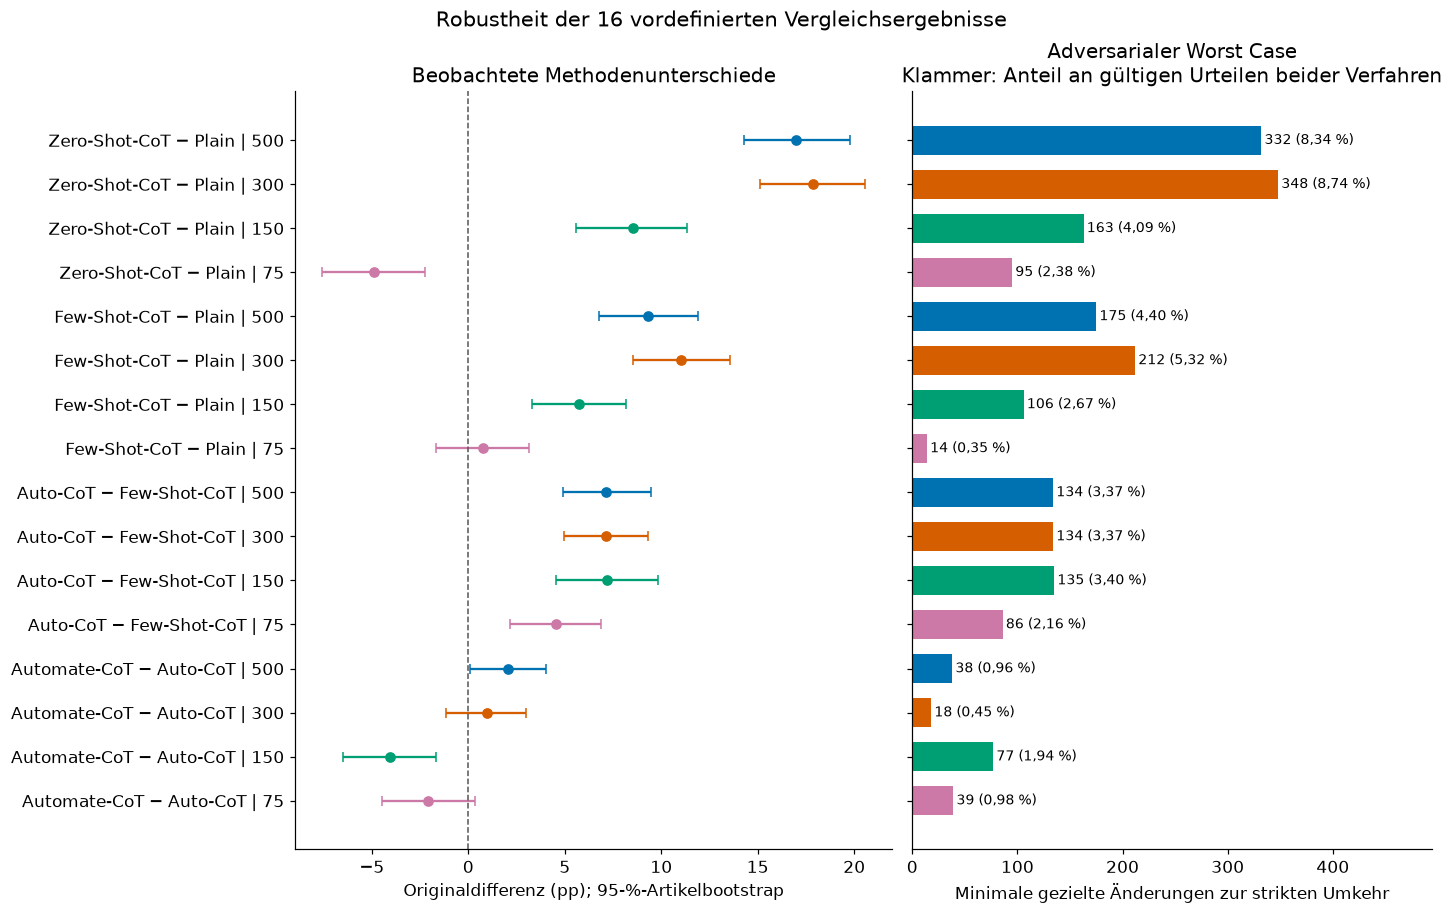

In [9]:
plot_rows=attacks.merge(original_contrasts[['first','second','stage_target_words','ci_low','ci_high']],
    on=['first','second','stage_target_words'],validate='one_to_one')
labels=[f'{NAMES[r.first]} − {NAMES[r.second]} | {r.stage_target_words}' for r in plot_rows.itertuples()]
fig,(ax,bx)=plt.subplots(1,2,figsize=(13,8.2),sharey=True,gridspec_kw={'width_ratios':[1.15,1]},layout='constrained')
ys=np.arange(len(plot_rows))
for y,r in zip(ys,plot_rows.itertuples()):
    ax.errorbar(r.original_difference_pp,y,xerr=[[r.original_difference_pp-r.ci_low],[r.ci_high-r.original_difference_pp]],
        fmt='o',color=STAGE_COLORS[r.stage_target_words],capsize=3)
    bx.barh(y,r.min_strict_reverse,color=STAGE_COLORS[r.stage_target_words],height=.65)
    bx.text(r.min_strict_reverse+3,y,f'{r.min_strict_reverse} ({de(r.min_reverse_percent_valid)} %)',va='center',fontsize=9)
ax.axvline(0,color='#555555',lw=1,ls='--')
ax.set(yticks=ys,yticklabels=labels,xlabel='Originaldifferenz (pp); 95-%-Artikelbootstrap')
ax.invert_yaxis()
ax.set_title('Beobachtete Methodenunterschiede')
bx.set(xlabel='Minimale gezielte Änderungen zur strikten Umkehr',xlim=(0,plot_rows.min_strict_reverse.max()*1.42))
bx.set_title('Adversarialer Worst Case\nKlammer: Anteil an gültigen Urteilen beider Verfahren')
fig.suptitle('Robustheit der 16 vordefinierten Vergleichsergebnisse',fontsize=14)
savefig(fig,'01_originaldifferenzen_und_minimale_aenderungen')

## 4. Analyse B: hypothetische Fehlerszenarien

### Modellannahmen und Simulationsplan

Alle Raten beziehen sich auf die **beobachteten**, nicht auf unbekannte wahre Labels:
\(p_{R\to N}\) ist die hypothetische Änderungswahrscheinlichkeit eines beobachteten
retained-Urteils zu 0; \(p_{N\to R}\) die eines beobachteten not_retained-Urteils zu 1.
Dies sind keine empirischen False-Negative-/False-Positive-Raten. Fehlwerte bleiben fix.
Die 40 regelbasierten NOT_FOUND-Positionen aus leeren generativen Ausgaben bleiben im
Originalwert enthalten; als gültige binäre Positionen gehören sie ebenfalls zum
abstrakten Änderungsuniversum. Das verdeutlicht, dass dies ein Stressmodell ohne
semantische Wahrheitsannahme für einzelne Änderungen ist.

1. **Symmetrisch, unabhängig:** beide Richtungen mit 0,5 / 1 / 2 / 3 / 5 / 10 %.
2. **Asymmetrisch, unabhängig:** Richtungspaare (1 %, 3 %), (3 %, 1 %), (2 %, 5 %),
   (5 %, 2 %), (0 %, 5 %), (5 %, 0 %). Beide Richtungen werden ergebnisneutral abgedeckt.
3. **Verfahrensabhängig, unabhängig:** Basis 2 % in beiden Richtungen für alle Methoden;
   jeweils eines der sechs Verfahren erhält zusätzlich 1 / 2 / 3 Prozentpunkte bei
   `R→N`. Jede Methode wird separat benachteiligt. Die Gegenrichtung bleibt 2 %.
   Das ist eine feste Richtungsannahme, kein empirischer Nachweis eines Paraphrasenbias.
4. **Artikelkorreliert:** symmetrisch dieselben sechs Raten. Ein einziger Bernoulli-Zug
   pro Artikel und Wiederholung kehrt **alle gültigen Labels dieses Artikels über alle
   Fakten, Methoden und Stufen gemeinsam** um. Die marginale Änderungsrate bleibt p,
   die Abhängigkeit ist absichtlich extrem. Dies ist eine Sensitivitätsvariante,
   keine Schätzung der tatsächlichen Korrelationsstruktur.

Es gibt 5.000 Wiederholungen je Szenario; ein fest aus Szenario-ID und Basis-Seed
32.026 abgeleiteter Seed hält die Ergebnisse auch bei Umordnung der Szenarien stabil.
Unabhängige Änderungen werden ohne Näherung als Binomialzahlen je ursprünglicher
Klasse und Artikelzelle gezogen: Alle Urteile einer solchen Klasse haben für die
hier untersuchten Metriken dasselbe Gewicht. Es müssen daher keine 48.000 Labels
pro Wiederholung kopiert oder überschrieben werden.

Erwartung bei gemeinsamen Richtungsraten:
\(E(R')=p_{N\to R}+(1-p_{R\to N}-p_{N\to R})R\).
Für symmetrische gemeinsame p gilt deshalb \(E(\Delta')=(1-2p)\Delta\): Im Mittel
werden Unterschiede abgeschwächt, ohne sich bei p < 50 % systematisch umzukehren.
Einzelne Simulationen können trotzdem Rangwechsel zeigen.

In [10]:
scenarios=[]
def add_scenario(sid,family,p_down,p_up,dependence='independent',focal='',extra=0.0):
    down=np.broadcast_to(np.asarray(p_down,dtype=float),(6,)).copy()
    up=np.broadcast_to(np.asarray(p_up,dtype=float),(6,)).copy()
    sid_seed=int.from_bytes(hashlib.sha256(sid.encode()).digest()[:4],'little')
    seed=int(np.random.SeedSequence([SIM_SEED,sid_seed]).generate_state(1)[0])
    scenarios.append(dict(id=sid,family=family,down=down,up=up,dependence=dependence,
        focal=focal,extra=extra,seed=seed))
for p in RATES:
    add_scenario(f'sym_{p:.3f}','symmetrisch',p,p)
for down,up in [(.01,.03),(.03,.01),(.02,.05),(.05,.02),(0,.05),(.05,0)]:
    add_scenario(f'asym_{down:.3f}_{up:.3f}','asymmetrisch',down,up)
for focal in METHODS:
    for extra in [.01,.02,.03]:
        down=np.full(6,.02);down[METHODS.index(focal)]+=extra
        add_scenario(f'method_{focal}_{extra:.2f}','verfahrensabhaengig',down,.02,focal=focal,extra=extra)
for p in RATES:
    add_scenario(f'article_{p:.3f}','artikelkorreliert',p,p,dependence='article')
scenario_by_id={s['id']:s for s in scenarios}
assert len(scenarios)==36
scenario_rows=[]
for s in scenarios:
    for m,down,up in zip(METHODS,s['down'],s['up']):
        scenario_rows.append(dict(scenario=s['id'],family=s['family'],method=m,
            p_R_to_N=down,p_N_to_R=up,dependence=s['dependence'],focal_method=s['focal'],
            extra_adverse_pp=100*s['extra'],seed=s['seed'],n_repeats=REPEATS))
scenario_table=pd.DataFrame(scenario_rows)
export(scenario_table,'B_szenariodefinitionen_und_seeds')
display(scenario_table.drop_duplicates('scenario')[['scenario','family','dependence','focal_method','extra_adverse_pp','seed','n_repeats']])

,scenario,family,dependence,focal_method,extra_adverse_pp,seed,n_repeats
0,sym_0.005,symmetrisch,independent,,0.0,3166055118,5000
6,sym_0.010,symmetrisch,independent,,0.0,3073616922,5000
12,sym_0.020,symmetrisch,independent,,0.0,2752430470,5000
18,sym_0.030,symmetrisch,independent,,0.0,855890015,5000
24,sym_0.050,symmetrisch,independent,,0.0,1173945285,5000
...,...,...,...,...,...,...,...
186,article_0.010,artikelkorreliert,article,,0.0,695630830,5000
192,article_0.020,artikelkorreliert,article,,0.0,2661947951,5000
198,article_0.030,artikelkorreliert,article,,0.0,2000391130,5000
204,article_0.050,artikelkorreliert,article,,0.0,684681615,5000


In [11]:
def simulate(scenario,repeats=REPEATS):
    rng=np.random.default_rng(scenario['seed'])
    down=scenario['down'][None,None,:,None]
    up=scenario['up'][None,None,:,None]
    raw_scores=np.empty((repeats,6,4),dtype=np.int64)
    adj_means=np.empty((repeats,6,4),dtype=float)
    down_totals=np.empty(repeats,dtype=np.int64)
    up_totals=np.empty(repeats,dtype=np.int64)
    for start in range(0,repeats,BATCH):
        stop=min(start+BATCH,repeats)
        size=stop-start
        if scenario['dependence']=='article':
            assert np.all(scenario['down']==scenario['down'][0]) and np.all(scenario['up']==scenario['down'][0])
            flipped=(rng.random((size,len(IDS),1,1))<scenario['down'][0])
            n_down=flipped*K[None,:,:,:]
            n_up=flipped*(V-K)[None,:,:,:]
        else:
            n_down=rng.binomial(K[None,:,:,:],down,size=(size,len(IDS),6,4))
            n_up=rng.binomial((V-K)[None,:,:,:],up,size=(size,len(IDS),6,4))
        new_counts=K[None,:,:,:]-n_down+n_up
        assert np.all(new_counts>=0) and np.all(new_counts<=V[None,:,:,:])
        raw_scores[start:stop]=(new_counts*RAW_SCALE).sum(axis=1)
        adj_means[start:stop]=(new_counts/20*PENALTY).mean(axis=1)
        down_totals[start:stop]=n_down.sum(axis=(1,2,3))
        up_totals[start:stop]=n_up.sum(axis=(1,2,3))
    return dict(raw_scores=raw_scores,adjusted=adj_means,n_down=down_totals,n_up=up_totals)

# Aussagekräftige Randprüfungen: keine Änderungen bzw. vollständiges Umkehren aller gültigen Positionen.
for probability in [0.,1.]:
    boundary=dict(id='boundary',down=np.full(6,probability),up=np.full(6,probability),dependence='independent',seed=123)
    result=simulate(boundary,repeats=4)
    expected_counts=K if probability==0 else V-K
    assert np.array_equal(result['raw_scores'],np.broadcast_to((expected_counts*RAW_SCALE).sum(axis=0),(4,6,4)))
    assert np.allclose(result['adjusted'],(expected_counts/20*PENALTY).mean(axis=0))
    assert np.all(result['n_down']+result['n_up']==(0 if probability==0 else qa.valid.sum()))

simulations={}
mc_check_rows=[]
for s in scenarios:
    result=simulate(s)
    simulations[s['id']]=result
    expected_counts=K*(1-s['down'][None,:,None])+(V-K)*s['up'][None,:,None]
    expected_raw=(expected_counts/V).mean(axis=0)
    expected_adj=(expected_counts/20*PENALTY).mean(axis=0)
    for metric,draws,expectation in [('raw',result['raw_scores']/(LCM*len(IDS)),expected_raw),
                                     ('adjusted',result['adjusted'],expected_adj)]:
        standard_error=draws.std(axis=0,ddof=1)/np.sqrt(REPEATS)
        difference=np.abs(draws.mean(axis=0)-expectation)
        z=np.divide(difference,standard_error,out=np.zeros_like(difference),where=standard_error>0)
        mc_check_rows.append(dict(scenario=s['id'],metric=metric,
            max_abs_mean_deviation_pp=float(100*difference.max()),max_MC_standard_errors=float(z.max()),
            analytic_expectation_check=bool(np.all(difference<=6*standard_error+1e-12))))
mc_checks=pd.DataFrame(mc_check_rows)
export(mc_checks,'B_abgleich_analytische_erwartungen')
assert mc_checks.analytic_expectation_check.all(), 'Monte-Carlo-Mittelwerte unerwartet weit vom analytischen Erwartungswert.'
scenario_realization=pd.DataFrame([dict(scenario=s['id'],n_repeats=REPEATS,
    n_valid_fixed=int(qa.valid.sum()),mean_flips=float((simulations[s['id']]['n_down']+simulations[s['id']]['n_up']).mean()),
    mean_flip_percent=pct((simulations[s['id']]['n_down']+simulations[s['id']]['n_up']).mean(),int(qa.valid.sum())),
    mean_R_to_N=float(simulations[s['id']]['n_down'].mean()),mean_N_to_R=float(simulations[s['id']]['n_up'].mean()))
    for s in scenarios])
export(scenario_realization,'B_tatsaechlich_simulierte_aenderungszahlen')
pass  # Große Bootstrap-Zwischendatei wird nicht benötigt.
display(Markdown(f'**{len(scenarios)} Szenarien × {REPEATS:,} Wiederholungen abgeschlossen.** '
    'Alle Änderungen betreffen nur gültige temporäre Binärwerte. Randfälle und analytische Erwartungen geprüft.'))

**36 Szenarien × 5,000 Wiederholungen abgeschlossen.** Alle Änderungen betreffen nur gültige temporäre Binärwerte. Randfälle und analytische Erwartungen geprüft.

### Simulationsbereiche und Vorzeichenwechsel

Die 2,5-%-/97,5-%-Quantile sind **Simulationsbereiche bei festen Artikeln**,
keine Bootstrap-Konfidenzintervalle. Die Monte-Carlo-Standardfehler beschreiben nur
die endliche Zahl von Wiederholungen. Vorzeichenumkehr, Gleichstand und Beibehalten
der ursprünglichen Richtung werden getrennt gezählt. Bei 5.000 Wiederholungen beträgt
der maximale Monte-Carlo-Standardfehler eines Anteils etwa 0,71 Prozentpunkte.

In [12]:
def direction(x):
    return np.where(np.abs(x)<=1e-10,0,np.sign(x)).astype(int)

contrast_sim_rows=[]
group_sim_rows=[]
for s in scenarios:
    sid=s['id'];result=simulations[sid]
    for metric,draws,original in [('raw',result['raw_scores']/(LCM*len(IDS)),ORIG_RAW),
                                   ('adjusted',result['adjusted'],ORIG_ADJ)]:
        for mi,m in enumerate(METHODS):
            for ti,t in enumerate(STAGES):
                values=100*draws[:,mi,ti]
                group_sim_rows.append(dict(scenario=sid,family=s['family'],metric=metric,method=m,
                    stage_target_words=t,original_percent=100*original[mi,ti],simulation_mean_percent=float(values.mean()),
                    sim_q025=float(np.quantile(values,.025)),sim_q975=float(np.quantile(values,.975)),
                    mean_MC_se_pp=float(values.std(ddof=1)/np.sqrt(REPEATS)),n_repeats=REPEATS))
        for first,second in CONTRASTS:
            i,j=METHODS.index(first),METHODS.index(second)
            for ti,t in enumerate(STAGES):
                values=100*(draws[:,i,ti]-draws[:,j,ti])
                orig=100*(original[i,ti]-original[j,ti])
                dirs=direction(values);sign=int(direction(orig))
                n_rev=int(np.sum(dirs*sign<0));n_tie=int(np.sum(dirs==0));n_same=int(np.sum(dirs==sign))
                assert n_rev+n_tie+n_same==REPEATS
                p=n_rev/REPEATS
                contrast_sim_rows.append(dict(scenario=sid,family=s['family'],metric=metric,first=first,second=second,
                    stage_target_words=t,original_difference_pp=orig,simulation_mean_difference_pp=float(values.mean()),
                    sim_q025_pp=float(np.quantile(values,.025)),sim_q975_pp=float(np.quantile(values,.975)),
                    mean_MC_se_pp=float(values.std(ddof=1)/np.sqrt(REPEATS)),
                    n_reversals=n_rev,n_ties=n_tie,n_same_direction=n_same,n_repeats=REPEATS,
                    reversal_frequency_percent=100*p,tie_frequency_percent=pct(n_tie,REPEATS),
                    reversal_frequency_MC_se_pp=100*np.sqrt(p*(1-p)/REPEATS)))
sim_contrasts=pd.DataFrame(contrast_sim_rows)
sim_groups=pd.DataFrame(group_sim_rows)
export(sim_contrasts,'B_simulierte_kontraste_und_vorzeichenwechsel')
export(sim_groups,'B_simulierte_retention_mittelwerte')
selected_table=sim_contrasts[sim_contrasts.metric.eq('raw') & sim_contrasts.scenario.isin(
    ['sym_0.050','article_0.050','method_auto_cot_0.03'])]
display(selected_table[['scenario','first','second','stage_target_words','original_difference_pp',
    'simulation_mean_difference_pp','sim_q025_pp','sim_q975_pp','reversal_frequency_percent']].round(3))

,scenario,first,second,stage_target_words,original_difference_pp,simulation_mean_difference_pp,sim_q025_pp,sim_q975_pp,reversal_frequency_percent
128,sym_0.050,zero_shot_cot,plain,500,16.997,15.307,13.942,16.649,0.00
129,sym_0.050,zero_shot_cot,plain,300,17.843,16.055,14.635,17.440,0.00
130,sym_0.050,zero_shot_cot,plain,150,8.523,7.675,6.334,9.018,0.00
131,sym_0.050,zero_shot_cot,plain,75,-4.874,-4.391,-5.735,-3.038,0.00
132,sym_0.050,few_shot_cot,plain,500,9.299,8.387,7.023,9.755,0.00
...,...,...,...,...,...,...,...,...,...
1099,article_0.050,auto_cot,few_shot_cot,75,4.526,4.089,2.926,5.095,0.00
1100,article_0.050,automate_cot,auto_cot,500,2.039,1.833,0.849,2.639,0.02
1101,article_0.050,automate_cot,auto_cot,300,0.956,0.859,-0.065,1.769,3.40
1102,article_0.050,automate_cot,auto_cot,150,-4.051,-3.637,-4.635,-2.477,0.00


### Abbildung 2: Sensitivität gegenüber symmetrischen Änderungen

Punkte bei 0 % sind die tatsächlich beobachteten Originaldifferenzen. Kurven und
schattierte Bereiche ab 0,5 % sind ausschließlich hypothetische Simulationen mit
unabhängigen Änderungen. Die schattierten 95-%-Simulationsbereiche enthalten keine
Artikel-Stichprobenunsicherheit. Die korrelierte Variante steht separat in den Tabellen
und in der Rangfolgenabbildung, damit ihre wesentlich andere Abhängigkeitsannahme sichtbar bleibt.

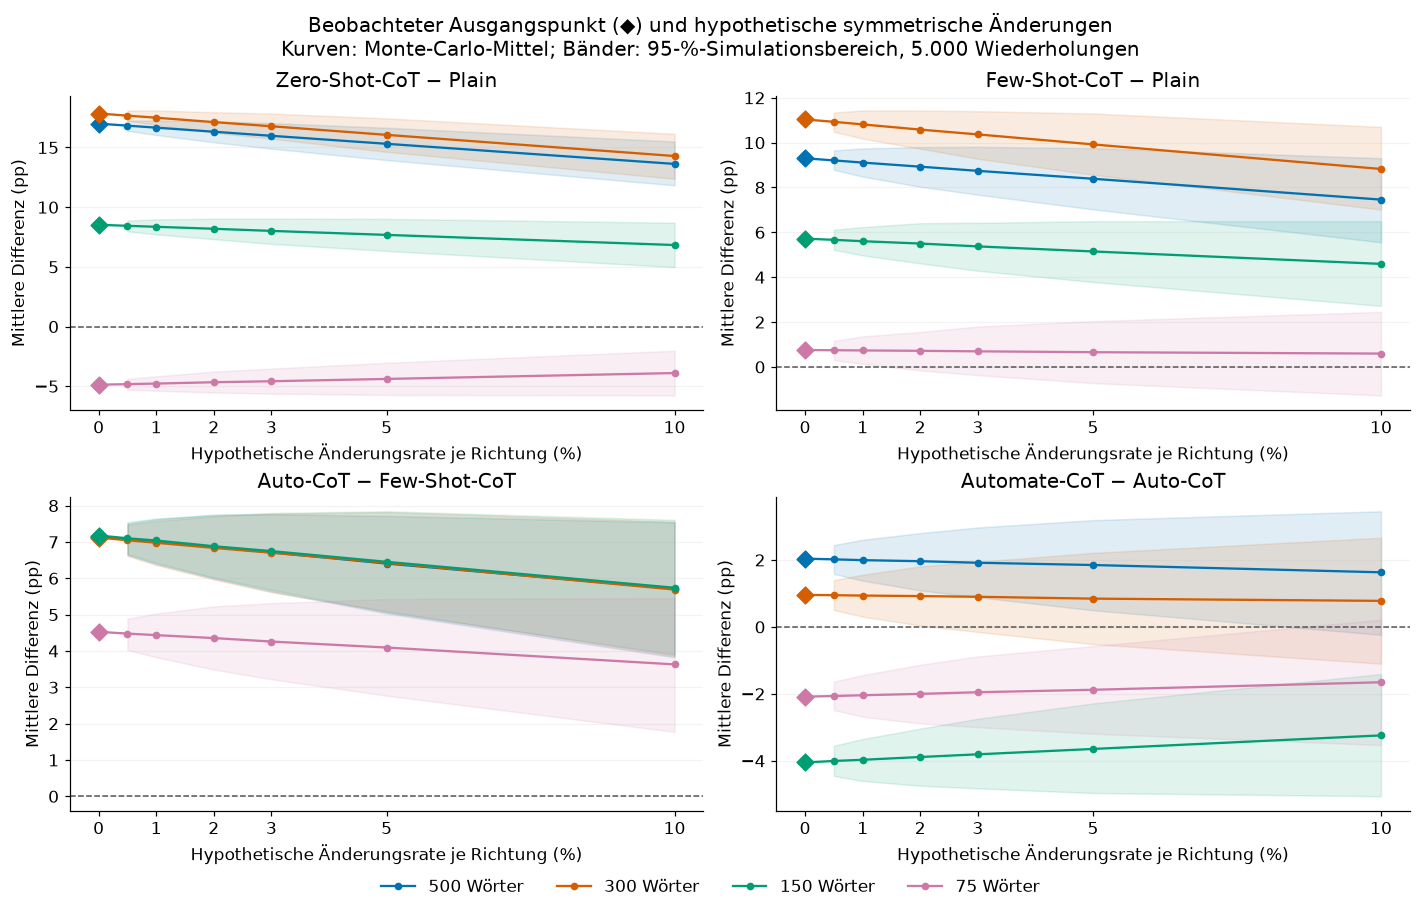

In [13]:
fig,axes=plt.subplots(2,2,figsize=(12.8,8.2),layout='constrained')
for ax,(first,second) in zip(axes.flat,CONTRASTS):
    for stage in STAGES:
        rows=sim_contrasts[(sim_contrasts.metric=='raw') & (sim_contrasts.family=='symmetrisch') &
            (sim_contrasts['first']==first) & (sim_contrasts.second==second) & sim_contrasts.stage_target_words.eq(stage)].copy()
        rows['rate']=[100*scenario_by_id[sid]['down'][0] for sid in rows.scenario]
        rows=rows.sort_values('rate')
        original=float(rows.original_difference_pp.iloc[0])
        ax.plot([0]+rows.rate.tolist(),[original]+rows.simulation_mean_difference_pp.tolist(),
            marker='o',ms=4,color=STAGE_COLORS[stage],label=f'{stage} Wörter')
        ax.fill_between(rows.rate.to_numpy(),rows.sim_q025_pp.to_numpy(),rows.sim_q975_pp.to_numpy(),
            color=STAGE_COLORS[stage],alpha=.12)
        ax.scatter([0],[original],color=STAGE_COLORS[stage],s=60,marker='D',zorder=3)
    ax.axhline(0,color='#555555',lw=1,ls='--')
    ax.set(xlabel='Hypothetische Änderungsrate je Richtung (%)',ylabel='Mittlere Differenz (pp)',xticks=[0,1,2,3,5,10])
    ax.set_title(f'{NAMES[first]} − {NAMES[second]}')
    ax.grid(axis='y',alpha=.15)
handles,labels=axes.flat[0].get_legend_handles_labels()
fig.legend(handles,labels,loc='outside lower center',ncol=4,frameon=False)
fig.suptitle('Beobachteter Ausgangspunkt (◆) und hypothetische symmetrische Änderungen\n'
             'Kurven: Monte-Carlo-Mittel; Bänder: 95-%-Simulationsbereich, 5.000 Wiederholungen',fontsize=13)
savefig(fig,'02_symmetrische_szenarien_methodendifferenzen')

### Ergänzende Grafik: Welche Annahmen ändern die Richtung eines Vergleichs?

Vier Teilgrafiken zeigen die Häufigkeit einer **strikten Vorzeichenumkehr** in jeweils 5.000 Simulationen. Verglichen werden symmetrische, artikelkorrelierte und gezielt verfahrensabhängige Szenarien. Bei letzteren gilt für das benannte Verfahren R→N = 5 %, für die übrigen R→N = 2 % und für alle N→R = 2 %. Die Farben sind Szenarioergebnisse, keine geschätzten realen Fehler- oder Überlegenheitswahrscheinlichkeiten.

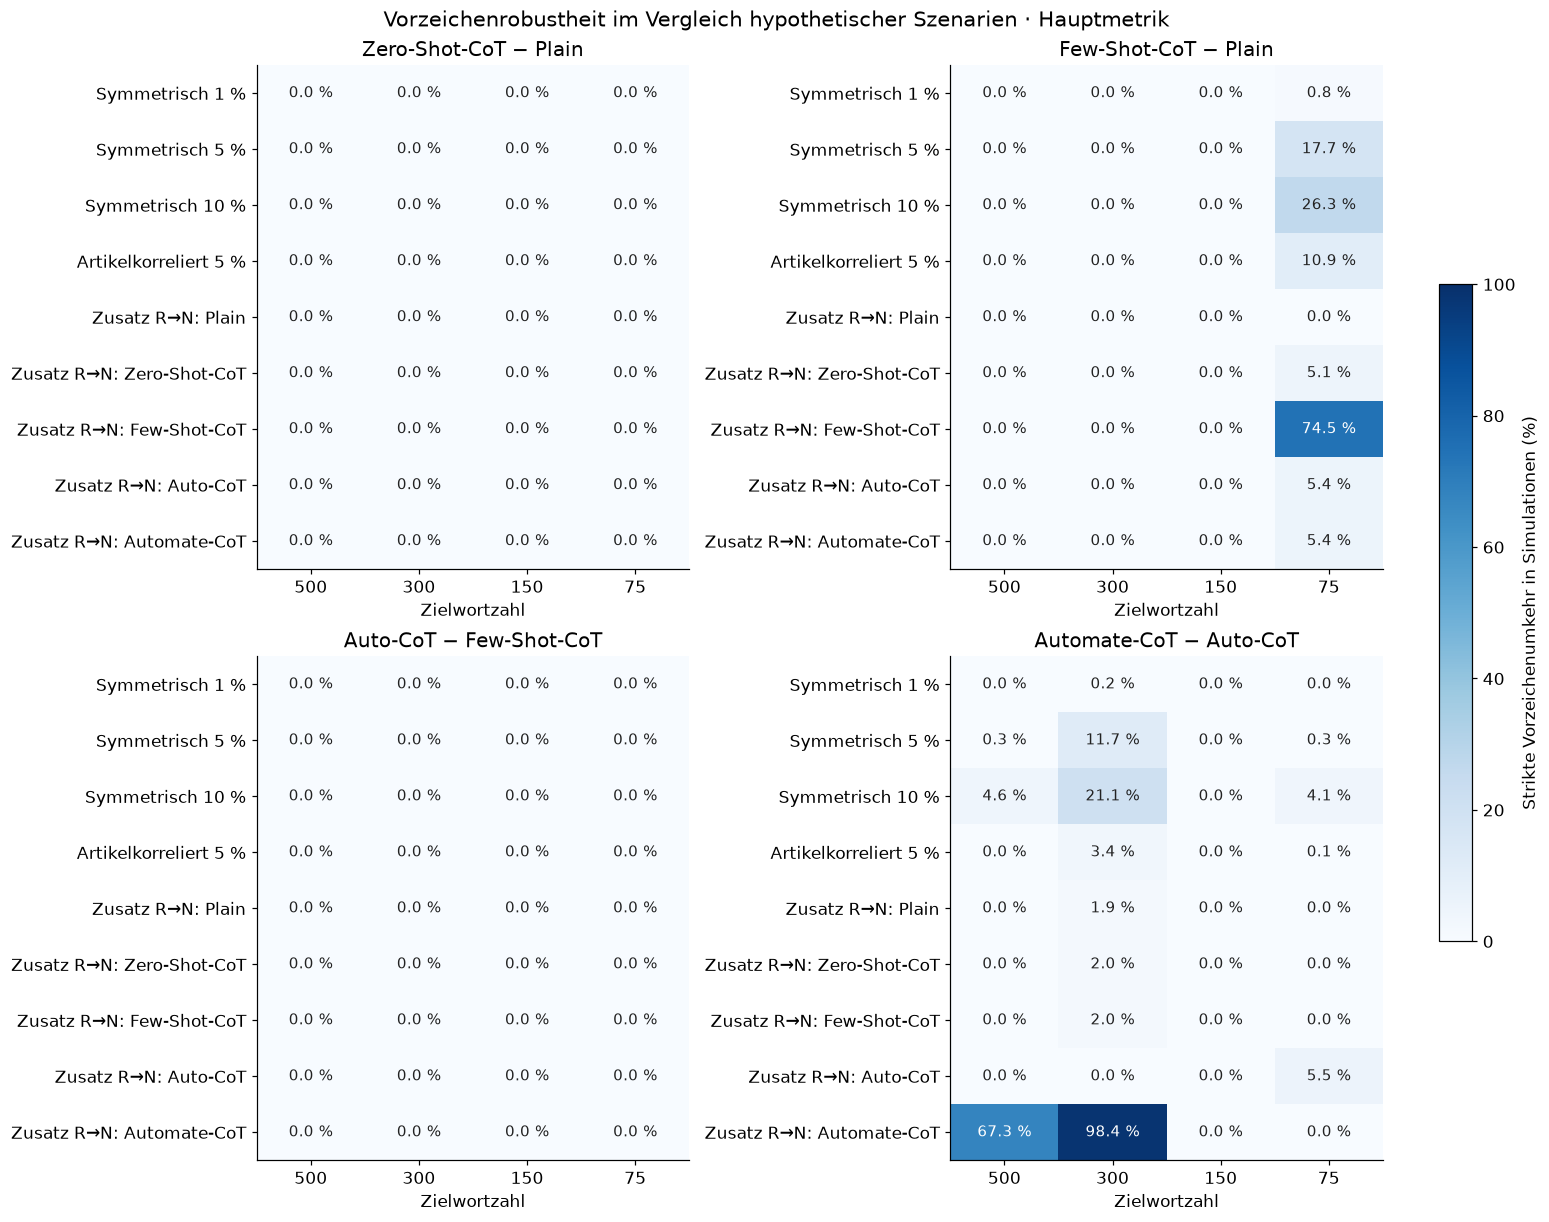

**Beobachtung:** Der höchste Anteil strikter Vorzeichenumkehr in dieser Szenarioauswahl beträgt 98,4 % bei Automate-CoT − Auto-CoT auf der 300-Wort-Stufe (Zusatz R→N: Automate-CoT). Das Ergebnis gilt nur unter der bezeichneten hypothetischen Änderungsannahme.

In [14]:
scenario_labels = {
    'sym_0.010':'Symmetrisch 1 %', 'sym_0.050':'Symmetrisch 5 %', 'sym_0.100':'Symmetrisch 10 %',
    'article_0.050':'Artikelkorreliert 5 %',
    **{f'method_{m}_0.03':f'Zusatz R→N: {NAMES[m]}' for m in METHODS[1:]}}
fig, axes = plt.subplots(2,2,figsize=(14,11),layout='constrained')
scenario_plot_rows=[]
for ax,(first,second) in zip(axes.flat, CONTRASTS):
    sub=sim_contrasts[sim_contrasts.metric.eq('raw') & sim_contrasts['first'].eq(first) & sim_contrasts.second.eq(second)]
    matrix=sub.pivot(index='scenario',columns='stage_target_words',values='reversal_frequency_percent').reindex(
        index=list(scenario_labels),columns=STAGES)
    assert matrix.notna().all().all()
    im=ax.imshow(matrix.to_numpy(),cmap='Blues',vmin=0,vmax=100,aspect='auto')
    for i,sid in enumerate(matrix.index):
        for j,stage in enumerate(STAGES):
            value=matrix.iloc[i,j]
            ax.text(j,i,f'{value:.1f} %',ha='center',va='center',color='white' if value>55 else '#222222',fontsize=10)
            scenario_plot_rows.append(dict(first=first,second=second,scenario=sid,stage_target_words=stage,
                reversal_frequency_percent=value,n_repeats=REPEATS))
    ax.set(xticks=range(4),xticklabels=STAGES,yticks=range(len(matrix)),yticklabels=list(scenario_labels.values()),
           xlabel='Zielwortzahl',title=f'{NAMES[first]} − {NAMES[second]}')
fig.colorbar(im,ax=axes.ravel().tolist(),shrink=.6,label='Strikte Vorzeichenumkehr in Simulationen (%)')
fig.suptitle('Vorzeichenrobustheit im Vergleich hypothetischer Szenarien · Hauptmetrik',fontsize=14)
export(pd.DataFrame(scenario_plot_rows),'grafik_szenarienvergleich_vorzeichenumkehr')
savefig(fig,'04_szenarienvergleich_vorzeichenumkehr')
worst=pd.DataFrame(scenario_plot_rows).sort_values('reversal_frequency_percent',ascending=False).iloc[0]
display(Markdown(f'**Beobachtung:** Der höchste Anteil strikter Vorzeichenumkehr in dieser Szenarioauswahl beträgt '
    f'{de(worst.reversal_frequency_percent,1)} % bei {NAMES[worst["first"]]} − {NAMES[worst.second]} '
    f'auf der {worst.stage_target_words}-Wort-Stufe ({scenario_labels[worst.scenario]}). '
    'Das Ergebnis gilt nur unter der bezeichneten hypothetischen Änderungsannahme.'))

## 5. Analyse C: Rangfolgenrobustheit

Je Szenario und Stufe werden die Häufigkeiten aller Rangplätze für alle sechs
Verfahren berechnet. Echte Gleichstände erhalten den gleichen Wettbewerbsrang.
Die Ranghäufigkeiten summieren sich **für jede Methode** auf 100 %, nicht zwingend
über Methoden innerhalb eines Rangplatzes. Ein geteilter erster Platz zählt separat
von einer alleinigen Spitzenposition.

Für die Hauptmetrik werden Ränge aus exakt ganzzahlig skalierten Summen gebildet
(kgV der festen gültigen Nenner). Die adjustierte Kennzahl nutzt wie die bestehende
Bootstrap-Ranganalyse float64; Differenzen bis 10⁻¹² gelten als numerischer Gleichstand.
Eine simulierte Ranghäufigkeit ist **keine Wahrscheinlichkeit tatsächlicher Überlegenheit**.

Die Längenstrafe und die Summaries bleiben in jeder Wiederholung fest. Zusätzlich wird
geprüft, ob beobachtete Rangverbesserungen/-verschlechterungen sowie Paarumkehrungen
durch Längenadjustierung in derselben Simulation erhalten bleiben.

Bei gemeinsamen symmetrischen Raten gilt für die adjustierte Kennzahl
\(E(R^{adj\prime}_m)=(1-2p)R^{adj}_m+p\,\overline{V_m/[20(1+D_m)]}\).
Der zweite Term hängt vom Verfahren ab. Deshalb kann eine gemeinsame symmetrische
Änderungsrate die **erwartete adjustierte Rangfolge** ändern, obwohl die erwarteten
Hauptmetrik-Differenzen lediglich mit \(1-2p\) skaliert werden. Dies ist eine Eigenschaft
der bereits vorhandenen Gewichtung, keine neu eingeführte Längenstrafe.

In [15]:
rank_frequency_rows=[]
leader_rows=[]
length_rank_rows=[]
length_pair_rows=[]
for s in scenarios:
    sid=s['id'];result=simulations[sid]
    ranks={
        'raw':rank_scores(result['raw_scores'].transpose(0,2,1)).transpose(0,2,1),
        'adjusted':rank_scores(result['adjusted'].transpose(0,2,1),tol=1e-12).transpose(0,2,1)}
    for metric,original_scores,original_rank in [('raw',ORIG_RAW,original_ranks_raw),('adjusted',ORIG_ADJ,original_ranks_adj)]:
        sim_rank=ranks[metric]
        for mi,m in enumerate(METHODS):
            for ti,t in enumerate(STAGES):
                for rank in range(1,7):
                    n=int(np.sum(sim_rank[:,mi,ti]==rank))
                    rank_frequency_rows.append(dict(scenario=sid,family=s['family'],metric=metric,method=m,
                        stage_target_words=t,rank=rank,n=n,n_repeats=REPEATS,frequency_percent=pct(n,REPEATS)))
        for ti,t in enumerate(STAGES):
            leader_indices=np.flatnonzero(original_rank[:,ti]==1)
            unique=(sim_rank[:,:,ti]==1).sum(axis=1)==1
            for mi in leader_indices:
                kept=sim_rank[:,mi,ti]==1
                leader_rows.append(dict(scenario=sid,family=s['family'],metric=metric,stage_target_words=t,
                    original_leader=METHODS[mi],n_repeats=REPEATS,
                    rank1_kept_percent=pct(kept.sum(),REPEATS),
                    sole_rank1_kept_percent=pct((kept&unique).sum(),REPEATS),
                    full_original_rank_vector_percent=pct(np.all(sim_rank[:,:,ti]==original_rank[:,ti],axis=1).sum(),REPEATS)))
    for mi,m in enumerate(METHODS):
        for ti,t in enumerate(STAGES):
            original_change=int(np.sign(original_ranks_adj[mi,ti]-original_ranks_raw[mi,ti]))
            sim_change=np.sign(ranks['adjusted'][:,mi,ti]-ranks['raw'][:,mi,ti])
            length_rank_rows.append(dict(scenario=sid,family=s['family'],method=m,stage_target_words=t,
                original_raw_rank=int(original_ranks_raw[mi,ti]),original_adjusted_rank=int(original_ranks_adj[mi,ti]),
                original_rank_change_direction=original_change,
                same_adjustment_direction_percent=pct(np.sum(sim_change==original_change),REPEATS),
                same_original_rank_pair_percent=pct(np.sum((ranks['raw'][:,mi,ti]==original_ranks_raw[mi,ti]) &
                    (ranks['adjusted'][:,mi,ti]==original_ranks_adj[mi,ti])),REPEATS)))
    for i,j in combinations(range(6),2):
        for ti,t in enumerate(STAGES):
            raw0=int(direction(ORIG_RAW[i,ti]-ORIG_RAW[j,ti]))
            adj0=int(direction(ORIG_ADJ[i,ti]-ORIG_ADJ[j,ti]))
            raw_dir=direction(result['raw_scores'][:,i,ti]-result['raw_scores'][:,j,ti])
            adj_dir=direction(result['adjusted'][:,i,ti]-result['adjusted'][:,j,ti])
            length_pair_rows.append(dict(scenario=sid,family=s['family'],first=METHODS[i],second=METHODS[j],
                stage_target_words=t,original_raw_direction=raw0,original_adjusted_direction=adj0,
                originally_inverted_by_adjustment=raw0*adj0<0,
                simulation_inverted_by_adjustment_percent=pct(np.sum(raw_dir*adj_dir<0),REPEATS),
                both_original_directions_kept_percent=pct(np.sum((raw_dir==raw0)&(adj_dir==adj0)),REPEATS),
                n_repeats=REPEATS))
rank_frequencies=pd.DataFrame(rank_frequency_rows)
leaders=pd.DataFrame(leader_rows)
length_rank_stability=pd.DataFrame(length_rank_rows)
length_pair_stability=pd.DataFrame(length_pair_rows)
assert rank_frequencies.groupby(['scenario','metric','method','stage_target_words']).n.sum().eq(REPEATS).all()
export(rank_frequencies,'C_ranghaeufigkeiten_alle_szenarien')
export(leaders,'C_originalfuehrung_und_gesamtrangfolge')
export(length_rank_stability,'C_laengenadjustierung_rangaenderungen')
export(length_pair_stability,'C_laengenadjustierung_alle_15_paarordnungen')
display(leaders[leaders.scenario.isin(['sym_0.050','article_0.050','method_auto_cot_0.03'])][
    ['scenario','metric','stage_target_words','original_leader','rank1_kept_percent','sole_rank1_kept_percent','full_original_rank_vector_percent']].round(2))
display(length_pair_stability[length_pair_stability.originally_inverted_by_adjustment &
    length_pair_stability.scenario.eq('sym_0.050')][['first','second','stage_target_words',
        'both_original_directions_kept_percent','simulation_inverted_by_adjustment_percent']].round(2))
adjusted75=leaders[(leaders.scenario=='sym_0.050')&(leaders.metric=='adjusted')&leaders.stage_target_words.eq(75)].iloc[0]
raw75=leaders[(leaders.scenario=='sym_0.050')&(leaders.metric=='raw')&leaders.stage_target_words.eq(75)].iloc[0]
display(Markdown(f'**Metrikabhängige Rangstabilität:** Bei 75 Wörtern behält '
    f'{NAMES[adjusted75.original_leader]} im unabhängigen symmetrischen 5-%-Szenario '
    f'die adjustierte Führung in {de(adjusted75.rank1_kept_percent)} % der Simulationen; '
    f'bei der Hauptmetrik sind es {de(raw75.rank1_kept_percent)} %. '
    'Die Differenz hängt auch mit dem verfahrensabhängigen additiven Erwartungsterm der '
    'adjustierten Kennzahl zusammen und darf nicht als beobachteter Scorer-Bias interpretiert werden.'))

,scenario,metric,stage_target_words,original_leader,rank1_kept_percent,sole_rank1_kept_percent,full_original_rank_vector_percent
32,sym_0.050,raw,500,lead_k,99.80,99.80,74.02
33,sym_0.050,raw,300,automate_cot,85.40,85.40,44.84
34,sym_0.050,raw,150,auto_cot,100.00,100.00,66.10
35,sym_0.050,raw,75,auto_cot,99.74,99.74,82.00
36,sym_0.050,adjusted,500,lead_k,100.00,100.00,54.74
37,sym_0.050,adjusted,300,automate_cot,57.78,57.78,49.76
38,sym_0.050,adjusted,150,zero_shot_cot,90.44,90.44,53.00
39,sym_0.050,adjusted,75,auto_cot,13.22,13.22,8.22
208,method_auto_cot_0.03,raw,500,lead_k,100.00,100.00,99.98
209,method_auto_cot_0.03,raw,300,automate_cot,99.72,99.72,0.02


,first,second,stage_target_words,both_original_directions_kept_percent,simulation_inverted_by_adjustment_percent
241,lead_k,plain,300,80.42,80.42
263,plain,zero_shot_cot,75,100.00,100.00
279,zero_shot_cot,few_shot_cot,75,94.56,94.56
281,zero_shot_cot,auto_cot,300,55.96,55.96
282,zero_shot_cot,auto_cot,150,99.88,99.88
286,zero_shot_cot,automate_cot,150,64.54,64.54
287,zero_shot_cot,automate_cot,75,99.98,99.98
290,few_shot_cot,auto_cot,150,96.02,96.02
294,few_shot_cot,automate_cot,150,76.98,76.98
295,few_shot_cot,automate_cot,75,96.50,96.50


**Metrikabhängige Rangstabilität:** Bei 75 Wörtern behält Auto-CoT im unabhängigen symmetrischen 5-%-Szenario die adjustierte Führung in 13,22 % der Simulationen; bei der Hauptmetrik sind es 99,74 %. Die Differenz hängt auch mit dem verfahrensabhängigen additiven Erwartungsterm der adjustierten Kennzahl zusammen und darf nicht als beobachteter Scorer-Bias interpretiert werden.

### Abbildung 3: Ranghäufigkeiten unter drei ausgewählten Stressannahmen

Gezeigt werden unabhängige 5-%-Änderungen, artikelkorrelierte 5-%-Änderungen und eine
zusätzliche Benachteiligung von Auto-CoT um 3 pp (`R→N`: 5 %, Gegenrichtung 2 %;
andere Methoden jeweils 2 %). Diese Auswahl illustriert die drei unterschiedlichen
Mechanismen; die vollständigen Ergebnisse für **jede** benachteiligte Methode stehen
in den Exporttabellen. Die gesonderte adjustierte Grafik erlaubt den Vergleich der
Rangstabilität bei unveränderter Längenstrafe.
Zellen zeigen Prozentanteile; `·` bedeutet 0 %, `<0,1` einen positiven Anteil unter 0,1 %.

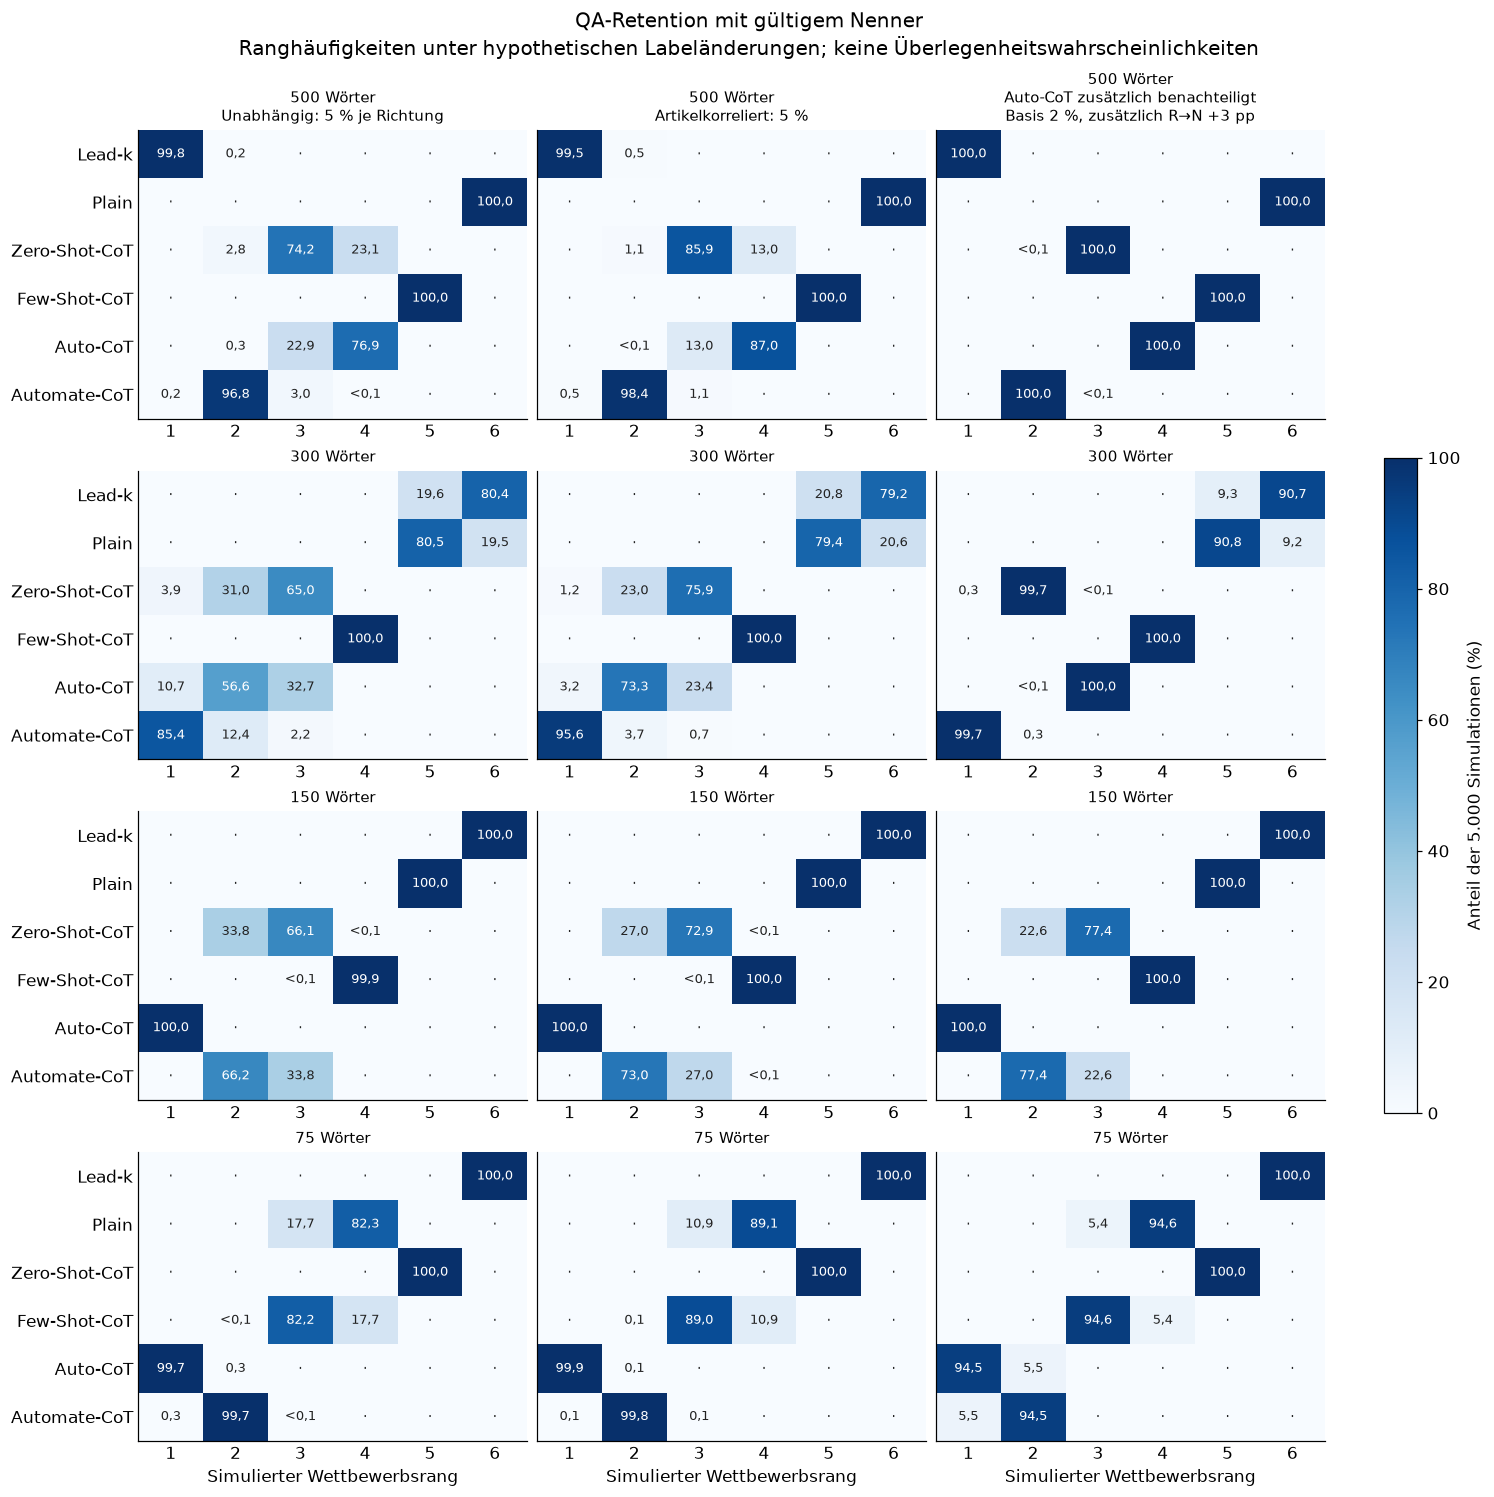

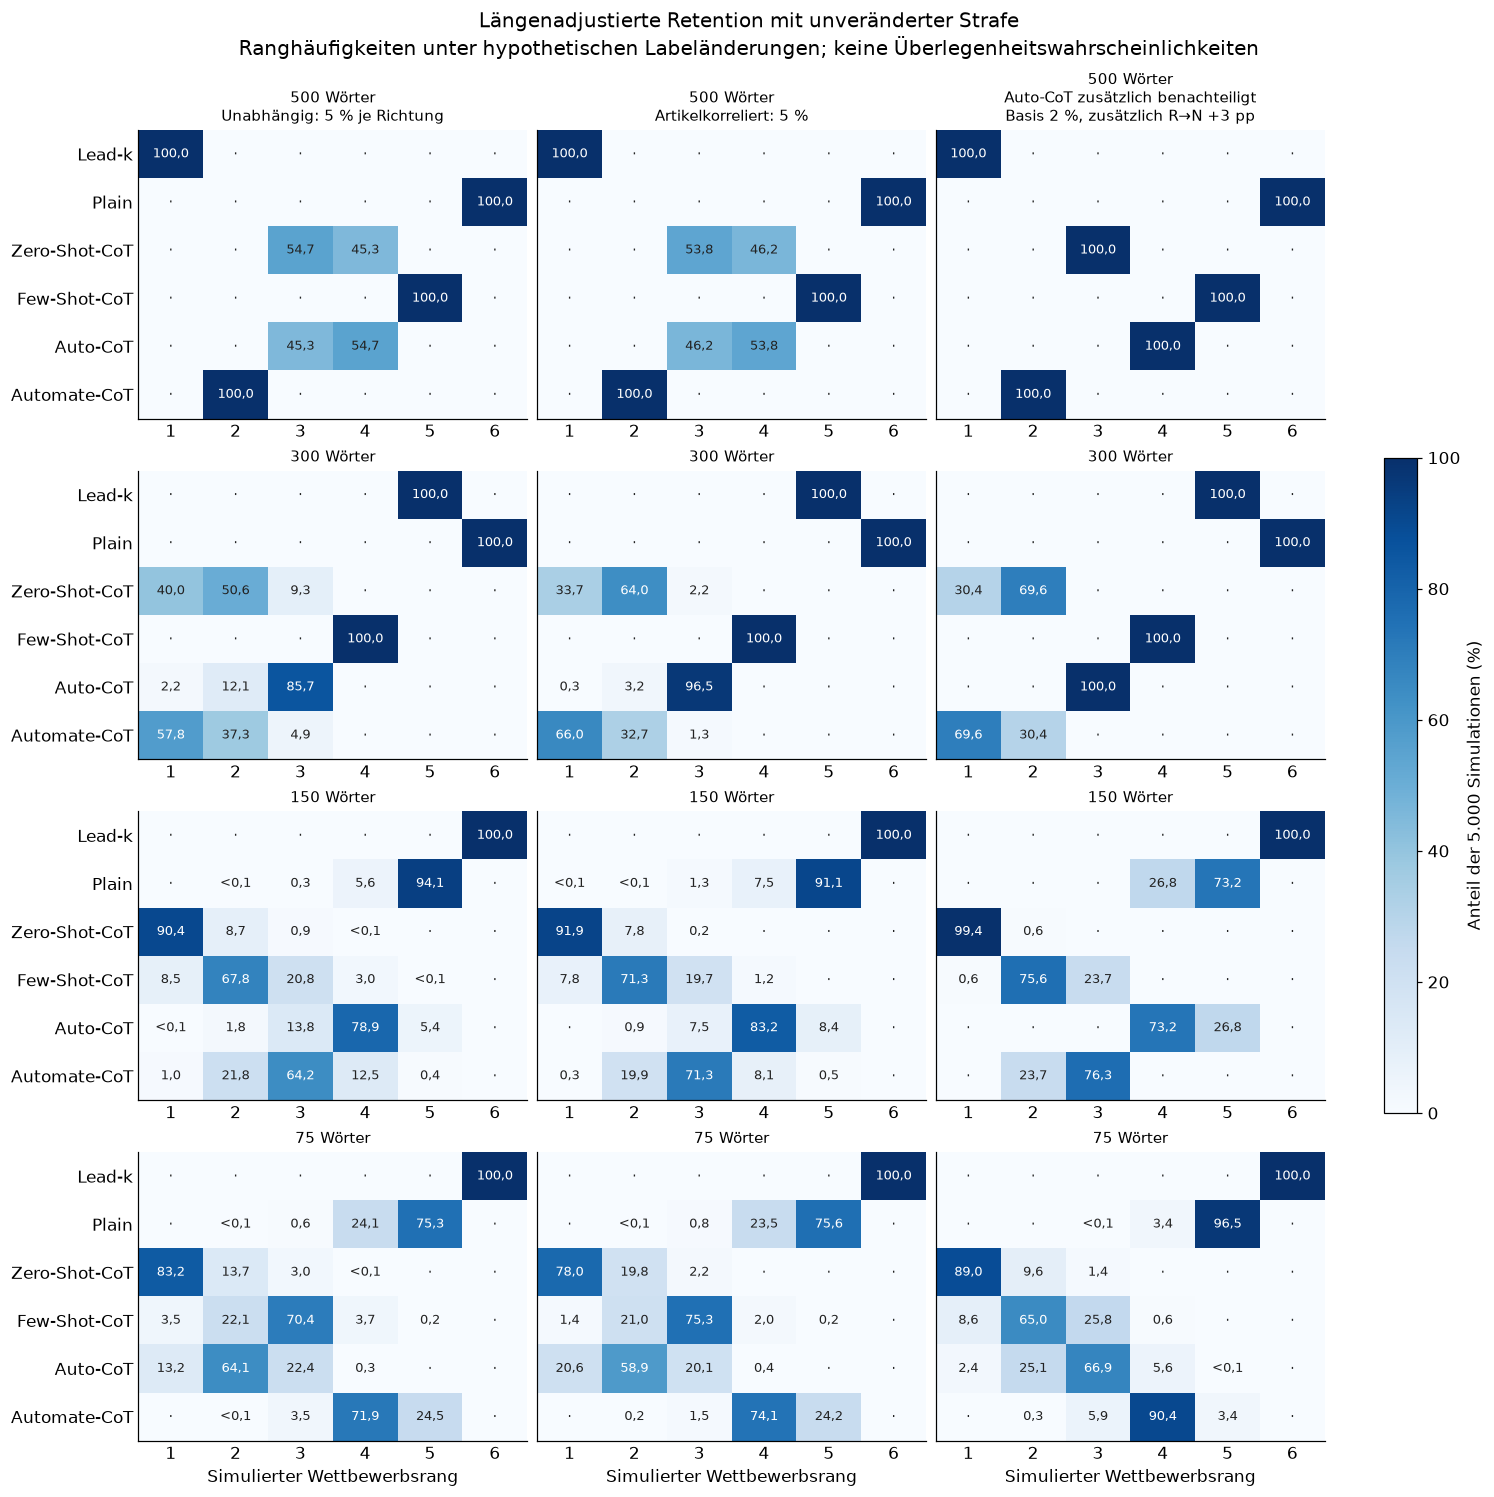

In [16]:
SELECTED=['sym_0.050','article_0.050','method_auto_cot_0.03']
SCENARIO_TITLES=['Unabhängig: 5 % je Richtung','Artikelkorreliert: 5 %',
                 'Auto-CoT zusätzlich benachteiligt\nBasis 2 %, zusätzlich R→N +3 pp']
def plot_rank_heatmaps(metric,name):
    fig,axes=plt.subplots(4,3,figsize=(13.5,13.5),layout='constrained')
    for ti,t in enumerate(STAGES):
        for si,sid in enumerate(SELECTED):
            ax=axes[ti,si]
            matrix=rank_frequencies[(rank_frequencies.scenario==sid)&(rank_frequencies.metric==metric)&
                rank_frequencies.stage_target_words.eq(t)].pivot(index='method',columns='rank',values='frequency_percent').reindex(METHODS).to_numpy()
            image=ax.imshow(matrix,cmap='Blues',vmin=0,vmax=100,aspect='auto')
            for i in range(6):
                for j in range(6):
                    value=matrix[i,j]
                    text='·' if value==0 else ('<0,1' if value<.1 else de(value,1))
                    ax.text(j,i,text,ha='center',va='center',fontsize=8.5,color='white' if value>=55 else '#222222')
            ax.set(xticks=range(6),xticklabels=range(1,7),yticks=range(6),
                yticklabels=[NAMES[m] for m in METHODS] if si==0 else [])
            ax.tick_params(length=0)
            ax.set_title(f'{t} Wörter'+ ('\n'+SCENARIO_TITLES[si] if ti==0 else ''),fontsize=10)
            if ti==3: ax.set_xlabel('Simulierter Wettbewerbsrang')
    fig.colorbar(image,ax=axes.ravel().tolist(),shrink=.5,label='Anteil der 5.000 Simulationen (%)')
    title='QA-Retention mit gültigem Nenner' if metric=='raw' else 'Längenadjustierte Retention mit unveränderter Strafe'
    fig.suptitle(title+'\nRanghäufigkeiten unter hypothetischen Labeländerungen; keine Überlegenheitswahrscheinlichkeiten',fontsize=13)
    savefig(fig,name)
plot_rank_heatmaps('raw','03a_rangrobustheit_qa_retention')
plot_rank_heatmaps('adjusted','03b_rangrobustheit_laengenadjustiert')

## 6. Analyse D: `reference_discordant` als unsichere Kategorie

Die konservative Variante entspricht exakt der Originalanalyse. In der maximal
permissiven Variante werden alle **gültigen** `reference_discordant`-Positionen
rechnerisch zusätzlich zum retained-Zähler gezählt. Gültige Nenner, technische
Fehlwerte und Längenstrafen bleiben unverändert. Auch hier wird kein Quelllabel ersetzt.

Dies ist eine hypothetische obere Variante **nur bezüglich dieser Kategorie**,
keine realistische Korrektur und keine allgemeine Obergrenze wahrer Faktenretention.
Mögliche Fehler innerhalb von `lost` oder falsch positive `retained`-Urteile bleiben
unberücksichtigt. Die deterministische Variante benötigt kein Zufallsmodell.

In [17]:
PERMISSIVE_RAW=((K+DISCORD)/V).mean(axis=0)
PERMISSIVE_ADJ=((K+DISCORD)/20*PENALTY).mean(axis=0)
assert np.all(K+DISCORD<=V)
deterministic_rows=[]
deterministic_contrasts=[]
for metric,conservative,permissive in [('raw',ORIG_RAW,PERMISSIVE_RAW),('adjusted',ORIG_ADJ,PERMISSIVE_ADJ)]:
    conservative_ranks=rank_scores(conservative.T,tol=1e-12).T
    permissive_ranks=rank_scores(permissive.T,tol=1e-12).T
    for mi,m in enumerate(METHODS):
        for ti,t in enumerate(STAGES):
            deterministic_rows.append(dict(metric=metric,method=m,stage_target_words=t,
                conservative_percent=100*conservative[mi,ti],permissive_percent=100*permissive[mi,ti],
                change_pp=100*(permissive[mi,ti]-conservative[mi,ti]),
                conservative_rank=int(conservative_ranks[mi,ti]),permissive_rank=int(permissive_ranks[mi,ti]),
                n_discordant=int(DISCORD[:,mi,ti].sum()),n_valid_fixed=int(V[:,mi,ti].sum())))
    for first,second in CONTRASTS:
        i,j=METHODS.index(first),METHODS.index(second)
        for ti,t in enumerate(STAGES):
            old=100*(conservative[i,ti]-conservative[j,ti])
            new=100*(permissive[i,ti]-permissive[j,ti])
            deterministic_contrasts.append(dict(metric=metric,first=first,second=second,stage_target_words=t,
                conservative_difference_pp=old,permissive_difference_pp=new,change_pp=new-old,
                strict_sign_reversal=bool(direction(old)*direction(new)<0),tie_after=bool(direction(new)==0)))
deterministic=pd.DataFrame(deterministic_rows)
permissive_contrasts=pd.DataFrame(deterministic_contrasts)
export(deterministic,'D_permissive_mittelwerte_und_raenge')
export(permissive_contrasts,'D_permissive_gepaarte_differenzen')
display(deterministic[deterministic.metric.eq('raw')][['method','stage_target_words','n_discordant','n_valid_fixed',
    'conservative_percent','permissive_percent','change_pp','conservative_rank','permissive_rank']].round(3))
display(permissive_contrasts[permissive_contrasts.metric.eq('raw')].round(3))
changed_ranks=deterministic[(deterministic.metric=='raw') &
    deterministic.conservative_rank.ne(deterministic.permissive_rank)]
display(Markdown(f'**Hauptmetrik:** '
    f'{int(permissive_contrasts[permissive_contrasts.metric.eq("raw")].strict_sign_reversal.sum())}/16 '
    f'vordefinierte Kontraste wechseln das Vorzeichen, aber {len(changed_ranks)}/24 '
    'Methoden-Stufen-Rangplätze ändern sich. Die vier Kontraste decken nicht alle 15 '
    'Methodenpaare ab; stabile Kontrastvorzeichen bedeuten daher keine vollständig stabile Rangfolge.'))

,method,stage_target_words,n_discordant,n_valid_fixed,conservative_percent,permissive_percent,change_pp,conservative_rank,permissive_rank
0,lead_k,500,87,1995,75.587,79.937,4.350,1,4
1,lead_k,300,100,1997,49.368,54.374,5.005,6,6
2,lead_k,150,107,1997,30.242,35.600,5.358,6,6
3,lead_k,75,87,1999,17.308,21.658,4.350,6,6
4,plain,500,228,1990,54.892,66.337,11.445,6,6
5,plain,300,250,1990,50.011,62.568,12.558,5,5
6,plain,150,250,1988,45.108,57.676,12.568,5,5
7,plain,75,230,1994,33.800,45.336,11.536,4,4
8,zero_shot_cot,500,214,1993,71.888,82.639,10.751,3,3
9,zero_shot_cot,300,234,1992,67.854,79.629,11.775,3,3


,metric,first,second,stage_target_words,conservative_difference_pp,permissive_difference_pp,change_pp,strict_sign_reversal,tie_after
0,raw,zero_shot_cot,plain,500,16.997,16.302,-0.694,False,False
1,raw,zero_shot_cot,plain,300,17.843,17.060,-0.783,False,False
2,raw,zero_shot_cot,plain,150,8.523,8.603,0.080,False,False
3,raw,zero_shot_cot,plain,75,-4.874,-6.739,-1.865,False,False
4,raw,few_shot_cot,plain,500,9.299,10.278,0.979,False,False
5,raw,few_shot_cot,plain,300,11.032,12.317,1.285,False,False
6,raw,few_shot_cot,plain,150,5.719,6.396,0.677,False,False
7,raw,few_shot_cot,plain,75,0.750,0.563,-0.187,False,False
8,raw,auto_cot,few_shot_cot,500,7.146,6.806,-0.340,False,False
9,raw,auto_cot,few_shot_cot,300,7.119,5.894,-1.225,False,False


**Hauptmetrik:** 0/16 vordefinierte Kontraste wechseln das Vorzeichen, aber 3/24 Methoden-Stufen-Rangplätze ändern sich. Die vier Kontraste decken nicht alle 15 Methodenpaare ab; stabile Kontrastvorzeichen bedeuten daher keine vollständig stabile Rangfolge.

### Ergänzende Grafik: Was ändert die permissive Referenzregel?

Offene Punkte zeigen die bestehende konservative Regel, ausgefüllte Punkte die hypothetische Umkodierung aller `reference_discordant`-Fälle zu `retained`. Die Verbindung ist die deterministische Änderung derselben Daten und kein Konfidenzintervall. Die Beschriftung nennt die Änderung in Prozentpunkten; die tatsächliche Korrektheit der Fälle ist unbekannt.

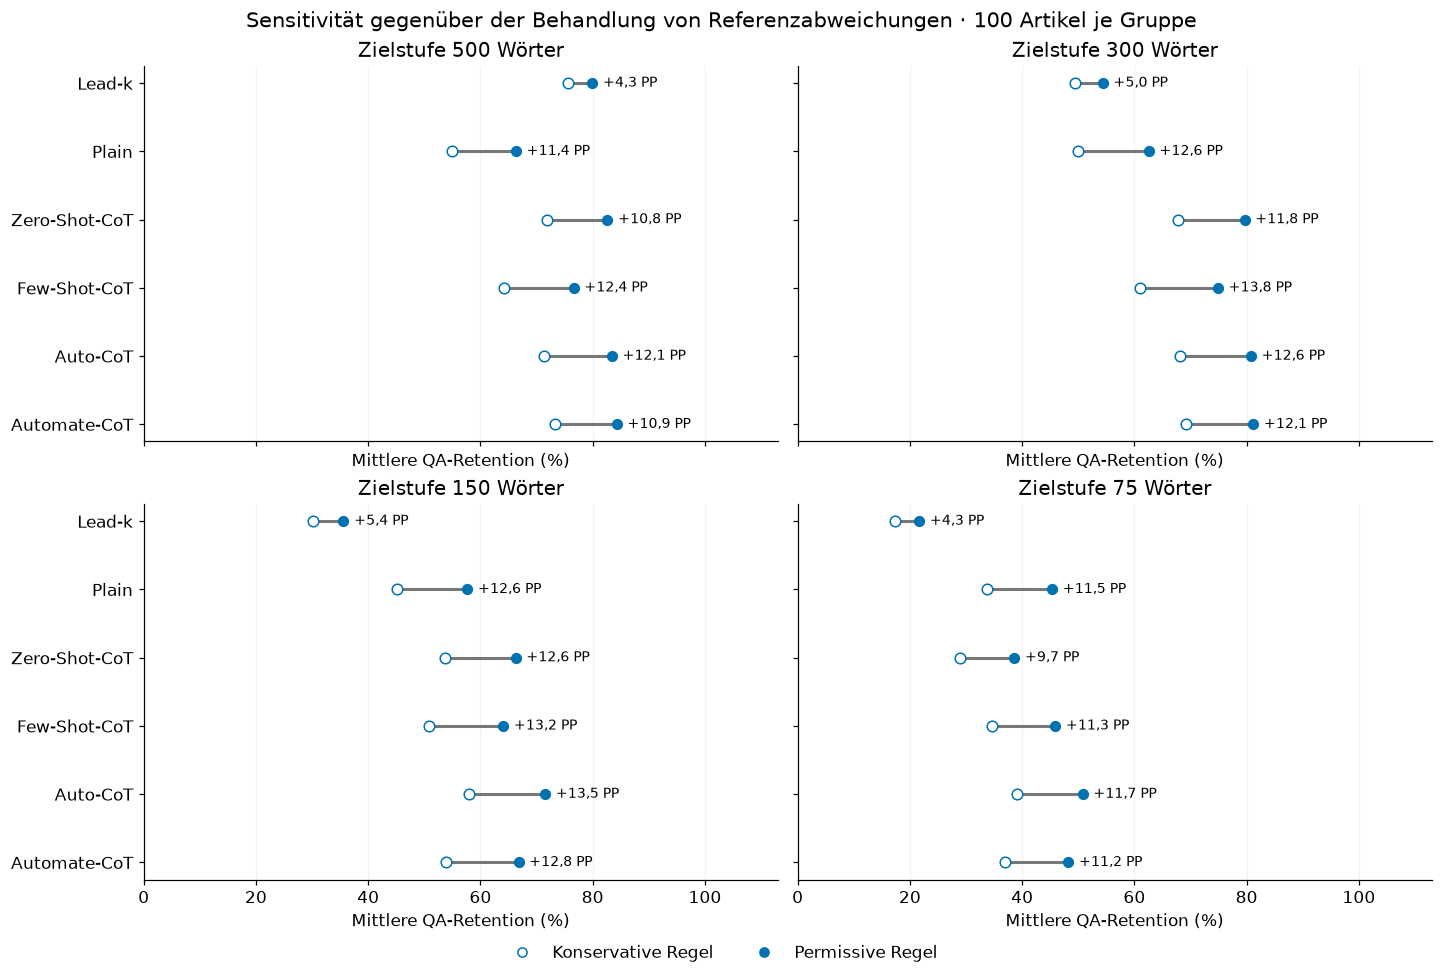

**Beobachtung:** Die permissive Regel erhöht die Retention je Verfahren und Stufe um 4,3 bis 13,8 Prozentpunkte. Die ungleichen Verschiebungen erklären, weshalb sich Rangplätze trotz stabiler Vorzeichen einzelner Kontraste ändern können.

In [18]:
fig,axes=plt.subplots(2,2,figsize=(13,8.8),sharex=True,sharey=True,layout='constrained')
for ax,stage in zip(axes.flat,STAGES):
    sub=deterministic[deterministic.metric.eq('raw') & deterministic.stage_target_words.eq(stage)].set_index('method').loc[METHODS]
    for i,(method,row) in enumerate(sub.iterrows()):
        ax.plot([row.conservative_percent,row.permissive_percent],[i,i],color='#777777',lw=2)
        ax.scatter(row.conservative_percent,i,facecolors='white',edgecolors='#0072B2',s=48,zorder=3)
        ax.scatter(row.permissive_percent,i,color='#0072B2',s=40,zorder=3)
        ax.annotate(f'+{de(row.change_pp,1)} PP',(row.permissive_percent,i),xytext=(7,0),textcoords='offset points',va='center',fontsize=9)
    ax.set(yticks=range(6),yticklabels=[NAMES[m] for m in METHODS],xlim=(0,113),
           xticks=range(0,101,20),xlabel='Mittlere QA-Retention (%)',title=f'Zielstufe {stage} Wörter')
    ax.grid(axis='x',alpha=.15)
axes[0,0].invert_yaxis()
fig.legend(handles=[plt.Line2D([0],[0],marker='o',mfc='white',color='#0072B2',ls='',label='Konservative Regel'),
                    plt.Line2D([0],[0],marker='o',color='#0072B2',ls='',label='Permissive Regel')],
           loc='outside lower center',ncol=2,frameon=False)
fig.suptitle('Sensitivität gegenüber der Behandlung von Referenzabweichungen · 100 Artikel je Gruppe',fontsize=14)
savefig(fig,'05_permissive_referenzregel_methodenvergleich')
shown=deterministic[deterministic.metric.eq('raw')]
display(Markdown(f'**Beobachtung:** Die permissive Regel erhöht die Retention je Verfahren und Stufe um '
    f'{de(shown.change_pp.min(),1)} bis {de(shown.change_pp.max(),1)} Prozentpunkte. '
    'Die ungleichen Verschiebungen erklären, weshalb sich Rangplätze trotz stabiler Vorzeichen einzelner Kontraste ändern können.'))

## 7. Zusammenfassung und Limitationen

### Verdichtete Ergebnistabellen

Die folgende Tabelle verbindet die ursprünglichen Differenzen, ihre gezielte
Worst-Case-Empfindlichkeit und die Sensitivität bei ausgewählten hypothetischen
Annahmen. Bootstrap-Intervalle und Simulationshäufigkeiten bleiben getrennt.
Umfangreiche Szenariotabellen sind für den Anhang vorgesehen.

In [19]:
main_table=attacks[['first','second','contrast','stage_target_words','original_difference_pp',
    'min_strict_reverse','min_reverse_percent_valid','n_articles_compact','n_articles_spread']].copy()
for sid,label in [('sym_0.050','sym5_reversal_percent'),('article_0.050','article5_reversal_percent')]:
    subset=sim_contrasts[(sim_contrasts.scenario==sid)&sim_contrasts.metric.eq('raw')][
        ['first','second','stage_target_words','reversal_frequency_percent']].rename(columns={'reversal_frequency_percent':label})
    main_table=main_table.merge(subset,on=['first','second','stage_target_words'],validate='one_to_one')
main_table=main_table.merge(permissive_contrasts[permissive_contrasts.metric.eq('raw')][
    ['first','second','stage_target_words','permissive_difference_pp','strict_sign_reversal']],
    on=['first','second','stage_target_words'],validate='one_to_one')
export(main_table,'haupttext_robustheit_16_vergleiche')
display(main_table.drop(columns=['first','second']).round(3))
compact_rows=pd.concat([main_table.nsmallest(2,'min_strict_reverse'),
                       main_table.nlargest(2,'min_strict_reverse')]).drop_duplicates(['first','second','stage_target_words'])
compact_table=compact_rows[['contrast','stage_target_words','original_difference_pp','min_strict_reverse','min_reverse_percent_valid']]
export(compact_table,'haupttext_kompakttabelle_4_befunde')
display(Markdown('**Platzsparende Haupttextauswahl:** die zwei kleinsten und zwei größten '
    'gezielten Änderungsbudgets; Auswahl deskriptiv nach der vollständig gezeigten 16-Zellen-Tabelle.'))
display(compact_table.round(3))
family_summary=sim_contrasts[sim_contrasts.metric.eq('raw')].groupby(['family','first','second','stage_target_words']).agg(
    min_scenario_reversal_percent=('reversal_frequency_percent','min'),
    max_scenario_reversal_percent=('reversal_frequency_percent','max'),n_scenarios=('scenario','nunique')).reset_index()
export(family_summary,'zusammenfassung_szenariofamilien_getrennt')
display(Markdown('Die Minima und Maxima je Szenariofamilie sind deskriptive Spannweiten über verschiedene Annahmen. '
    'Sie werden nicht zu einer gemeinsamen Fehler- oder Überlegenheitswahrscheinlichkeit gemittelt.'))

,contrast,stage_target_words,original_difference_pp,min_strict_reverse,min_reverse_percent_valid,n_articles_compact,n_articles_spread,sym5_reversal_percent,article5_reversal_percent,permissive_difference_pp,strict_sign_reversal
0,Zero-Shot-CoT − Plain,500,16.997,332,8.335,14,100,0.00,0.00,16.302,False
1,Zero-Shot-CoT − Plain,300,17.843,348,8.739,16,100,0.00,0.00,17.060,False
2,Zero-Shot-CoT − Plain,150,8.523,163,4.091,13,53,0.00,0.00,8.603,False
3,Zero-Shot-CoT − Plain,75,-4.874,95,2.380,5,45,0.00,0.00,-6.739,False
4,Few-Shot-CoT − Plain,500,9.299,175,4.404,14,19,0.00,0.00,10.278,False
5,Few-Shot-CoT − Plain,300,11.032,212,5.323,14,55,0.00,0.00,12.317,False
6,Few-Shot-CoT − Plain,150,5.719,106,2.668,8,19,0.00,0.00,6.396,False
7,Few-Shot-CoT − Plain,75,0.750,14,0.351,2,3,17.70,10.88,0.563,False
8,Auto-CoT − Few-Shot-CoT,500,7.146,134,3.374,9,19,0.00,0.00,6.806,False
9,Auto-CoT − Few-Shot-CoT,300,7.119,134,3.365,13,15,0.00,0.00,5.894,False


**Platzsparende Haupttextauswahl:** die zwei kleinsten und zwei größten gezielten Änderungsbudgets; Auswahl deskriptiv nach der vollständig gezeigten 16-Zellen-Tabelle.

,contrast,stage_target_words,original_difference_pp,min_strict_reverse,min_reverse_percent_valid
7,Few-Shot-CoT − Plain,75,0.750,14,0.351
13,Automate-CoT − Auto-CoT,300,0.956,18,0.453
1,Zero-Shot-CoT − Plain,300,17.843,348,8.739
0,Zero-Shot-CoT − Plain,500,16.997,332,8.335


Die Minima und Maxima je Szenariofamilie sind deskriptive Spannweiten über verschiedene Annahmen. Sie werden nicht zu einer gemeinsamen Fehler- oder Überlegenheitswahrscheinlichkeit gemittelt.

### Grenzen der Interpretation

- Die wirkliche Fehlerrate und ihre Abhängigkeit von Verfahren, Faktentyp, Artikel und
  Stufe sind unbekannt. Die Szenarien sind Annahmen, keine Messung dieser Größen.
- Geringe minimale Änderungszahlen zeigen Empfindlichkeit, nicht die Falschheit eines
  Ergebnisses. Hohe Zahlen schützen ebenfalls nicht gegen jede denkbare systematische
  Messverzerrung. Die Worst-Case-Lösungen wählen Änderungen gezielt und isoliert aus.
- Die alternativen Artikelzahlen bei minimalen Lösungen sind gefundene Beispiele mit
  demselben optimalen Gewichtsmultiset, keine vollständige Optimierung der Artikelzahl.
- Die symmetrische Erwartungsformel macht große Unterschiede im Mittel automatisch
  richtungsstabil. Diese Eigenschaft des Modells ist keine empirische Bestätigung des
  Scorers. Asymmetrische und verfahrensabhängige Annahmen sind separat zu beurteilen.
- Unabhängige Änderungen vernachlässigen gemeinsame Artikel-/Faktorenfehler. Die
  artikelkorrelierte Variante liefert einen bewusst starken Gegenpol, keine geschätzte
  Abhängigkeitsstruktur. Gemeinsam gezogene Artikel erhalten die vier Stufen zusammen.
- Die ursprünglichen Bootstrap-Intervalle enthalten Artikel-Stichprobenunsicherheit
  bei fixierten Labels. Monte-Carlo-Quantile enthalten nur hypothetische Labelvariation
  bei fixierten Artikeln. Beide werden weder vermischt noch zu einer scheinbar präzisen
  gemeinsamen Wahrscheinlichkeit verrechnet.
- Die Längenadjustierung verwendet zusätzlich den festen Nenner 20 und eine bereits
  festgelegte Strafe. Sie bewertet eine andere Größe als die Hauptmetrik und ist kein
  Nachweis tatsächlicher Informationsverluste. Summaries und Längen bleiben unverändert.
- Die permissive Variante beschränkt sich auf `reference_discordant`. Sie behebt weder
  fehlerhafte Referenzen noch mögliche Fehler in den anderen Klassen.
- Sämtliche Rangfolgen und ausgewählten Szenarien sind deskriptiv; es werden keine
  neuen bestätigenden Hypothesentests und keine unabhängig validierten Fehlerkorrekturen
  der Masterarbeit erzeugt. Die 196 technischen Fehlwerte bleiben unverändert fehlend.

### Wissenschaftlich relevante Ergebnisse für die Masterarbeit

Der folgende Kurztext entsteht ausschließlich aus den ausgeführten Berechnungen und
bleibt unter 250 Wörtern. Er ist als Material für höchstens eine halbe bis eine Seite
Haupttext gedacht; die vollständigen Szenarien gehören in den Anhang.

In [20]:
fragile=attacks.sort_values(['min_strict_reverse','stage_target_words']).head(2)
robust=attacks.sort_values('min_strict_reverse',ascending=False).iloc[0]
fragile_text='; '.join(f'{r.contrast} bei {r.stage_target_words} Wörtern: {r.min_strict_reverse} Änderungen '
    f'({de(r.min_reverse_percent_valid)} %)' for r in fragile.itertuples())
n_permissive_reversed=int(permissive_contrasts[permissive_contrasts.metric.eq('raw')].strict_sign_reversal.sum())
sym5=sim_contrasts[(sim_contrasts.metric=='raw')&(sim_contrasts.scenario=='sym_0.050')]
dep5=sim_contrasts[(sim_contrasts.metric=='raw')&(sim_contrasts.scenario=='article_0.050')]
leader5=leaders[(leaders.metric=='raw')&(leaders.scenario=='sym_0.050')]
worst_leader=leader5.sort_values('rank1_kept_percent').iloc[0]
adverse300=sim_contrasts[(sim_contrasts.scenario=='method_automate_cot_0.03') &
    (sim_contrasts.metric=='raw') & (sim_contrasts['first']=='automate_cot') &
    (sim_contrasts.second=='auto_cot') & sim_contrasts.stage_target_words.eq(300)].iloc[0]
large=attacks[attacks.original_difference_pp.abs().ge(5)]
all_scenarios_for_large=sim_contrasts[sim_contrasts.metric.eq('raw')].merge(
    large[['first','second','stage_target_words']],on=['first','second','stage_target_words'],validate='many_to_one')
stable_count=int((all_scenarios_for_large.groupby(['first','second','stage_target_words']).reversal_frequency_percent.max()<=1).sum())
chapter=(
    'Die Sensitivitätsanalyse reproduzierte alle ursprünglichen Retentionsmittelwerte, '
    'gepaarten Unterschiede und zugehörigen Artikelbootstrap-Intervalle sowie die längenadjustierten Ergebnisse. '
    'Technische Fehlwerte und Originalklassifikationen blieben unverändert.\n\n'
    f'Für eine gezielte strikte Vorzeichenumkehr waren je Vergleich und Stufe mindestens '
    f'{int(attacks.min_strict_reverse.min())} bis {int(attacks.min_strict_reverse.max())} Änderungen erforderlich. '
    f'Besonders empfindlich waren {fragile_text}. '
    f'Der größte Mindestbedarf betraf {robust.contrast} bei {robust.stage_target_words} Wörtern '
    f'({robust.min_strict_reverse} Änderungen). Dies sind adversariale Änderungsbudgets, keine Fehlerraten.\n\n'
    f'Unter unabhängigen symmetrischen 5-%-Änderungen lagen die simulierten Vorzeichenumkehranteile '
    f'zwischen {de(sym5.reversal_frequency_percent.min())} und {de(sym5.reversal_frequency_percent.max())} %. '
    f'Bei artikelkorrelierten 5-%-Änderungen reichte die Spannweite bis '
    f'{de(dep5.reversal_frequency_percent.max())} %. Die ursprüngliche Führung bei '
    f'{int(worst_leader.stage_target_words)} Wörtern blieb im unabhängigen 5-%-Szenario in '
    f'{de(worst_leader.rank1_kept_percent)} % der Simulationen erhalten. '
    'Rangfolgenstabilität hängt damit von Änderungsrichtung und Abhängigkeitsannahme ab; '
    'Ranghäufigkeiten sind keine Wahrscheinlichkeiten tatsächlicher Überlegenheit.\n\n'
    f'Bei zusätzlich 3 pp nachteiligen Änderungen für Automate-CoT kehrte sich dessen '
    f'300-Wörter-Vergleich zu Auto-CoT in {de(adverse300.reversal_frequency_percent)} % der Simulationen um. '
    f'Die adjustierte Auto-CoT-Führung bei 75 Wörtern blieb im unabhängigen 5-%-Szenario nur '
    f'in {de(adjusted75.rank1_kept_percent)} % erhalten.\n\n'
    f'Die maximal permissive Behandlung von reference_discordant kehrte '
    f'{n_permissive_reversed}/16 ursprünglichen Kontrastvorzeichen um. '
    'Die 500-Wörter-Führung wechselte dabei von Lead-k zu Automate-CoT. '
    'Große deskriptive Abstände sind unter den untersuchten Annahmen belastbarer als knappe '
    'Rangpositionen; eine allgemeine Verfahrensüberlegenheit oder Scorer-Genauigkeit folgt daraus nicht. '
    'Empfohlen wird ein Kurzabschnitt in Kapitel 4.2 mit der kompakten Vier-Zeilen-Tabelle. '
    'Die eigenständige Robustheitsabbildung 1 und Szenariotabellen gehören aus Platzgründen '
    'in den Anhang, die unbekannte reale Fehlerrate in die Limitationen.'
)
assert len(chapter.split())<=250,len(chapter.split())
(OUT/'Ergebniszusammenfassung_Masterarbeit_max250_Woerter.md').write_text(chapter+'\n',encoding='utf-8')
display(Markdown(chapter))
display(Markdown(f'*Automatisch erzeugt: {len(chapter.split())} Wörter.*'))

Die Sensitivitätsanalyse reproduzierte alle ursprünglichen Retentionsmittelwerte, gepaarten Unterschiede und zugehörigen Artikelbootstrap-Intervalle sowie die längenadjustierten Ergebnisse. Technische Fehlwerte und Originalklassifikationen blieben unverändert.

Für eine gezielte strikte Vorzeichenumkehr waren je Vergleich und Stufe mindestens 14 bis 348 Änderungen erforderlich. Besonders empfindlich waren Few-Shot-CoT − Plain bei 75 Wörtern: 14 Änderungen (0,35 %); Automate-CoT − Auto-CoT bei 300 Wörtern: 18 Änderungen (0,45 %). Der größte Mindestbedarf betraf Zero-Shot-CoT − Plain bei 300 Wörtern (348 Änderungen). Dies sind adversariale Änderungsbudgets, keine Fehlerraten.

Unter unabhängigen symmetrischen 5-%-Änderungen lagen die simulierten Vorzeichenumkehranteile zwischen 0,00 und 17,70 %. Bei artikelkorrelierten 5-%-Änderungen reichte die Spannweite bis 10,88 %. Die ursprüngliche Führung bei 300 Wörtern blieb im unabhängigen 5-%-Szenario in 85,40 % der Simulationen erhalten. Rangfolgenstabilität hängt damit von Änderungsrichtung und Abhängigkeitsannahme ab; Ranghäufigkeiten sind keine Wahrscheinlichkeiten tatsächlicher Überlegenheit.

Bei zusätzlich 3 pp nachteiligen Änderungen für Automate-CoT kehrte sich dessen 300-Wörter-Vergleich zu Auto-CoT in 98,40 % der Simulationen um. Die adjustierte Auto-CoT-Führung bei 75 Wörtern blieb im unabhängigen 5-%-Szenario nur in 13,22 % erhalten.

Die maximal permissive Behandlung von reference_discordant kehrte 0/16 ursprünglichen Kontrastvorzeichen um. Die 500-Wörter-Führung wechselte dabei von Lead-k zu Automate-CoT. Große deskriptive Abstände sind unter den untersuchten Annahmen belastbarer als knappe Rangpositionen; eine allgemeine Verfahrensüberlegenheit oder Scorer-Genauigkeit folgt daraus nicht. Empfohlen wird ein Kurzabschnitt in Kapitel 4.2 mit der kompakten Vier-Zeilen-Tabelle. Die eigenständige Robustheitsabbildung 1 und Szenariotabellen gehören aus Platzgründen in den Anhang, die unbekannte reale Fehlerrate in die Limitationen.

*Automatisch erzeugt: 234 Wörter.*

### Abschließende Integritätsprüfung

Kontrolliert werden Reproduktion, exakte Worst-Case-Grenzen, Simulationserwartungen,
Ranghäufigkeiten, unveränderte Quelllabels und sämtliche verwendeten Quellenhashes.
Das Ausführungsprotokoll hält die Annahmen und Softwareversionen fest.

In [21]:
assert hashlib.sha256(qa[KEY+['label']].to_csv(index=False).encode()).hexdigest()==original_label_digest
assert (~qa.valid).sum()==196
assert reproduction.bestanden.all() and length_reproduction.passed.all()
assert mc_checks.analytic_expectation_check.all()
assert np.all(attacks.min_strict_reverse>=attacks.min_tie_or_cross)
assert np.all(attacks.n_changes_first+attacks.n_changes_second==attacks.min_strict_reverse)
# Unabhängiger Abgleich der Minima aus Artikelzählungen und ganzzahligen kgV-Gewichten.
# Diese Prüfung braucht weder die Einzelurteil-Sortierung noch die Fraction-Präfixliste.
for row in attacks.itertuples():
    i,j=METHODS.index(row.first),METHODS.index(row.second)
    t=STAGES.index(row.stage_target_words)
    integer_gap=int(ORIG_RAW_SCORES[i,t]-ORIG_RAW_SCORES[j,t])
    available_first=K[:,i,t] if integer_gap>0 else V[:,i,t]-K[:,i,t]
    available_second=V[:,j,t]-K[:,j,t] if integer_gap>0 else K[:,j,t]
    possible_weights=np.concatenate([np.repeat(RAW_SCALE[:,i,t],available_first),
                                     np.repeat(RAW_SCALE[:,j,t],available_second)])
    cumulative=np.cumsum(np.sort(possible_weights)[::-1])
    assert np.searchsorted(cumulative,abs(integer_gap),side='left')+1==row.min_tie_or_cross
    assert np.searchsorted(cumulative,abs(integer_gap),side='right')+1==row.min_strict_reverse
assert rank_frequencies.groupby(['scenario','metric','method','stage_target_words']).n.sum().eq(REPEATS).all()
for source,digest in sources_before.items():
    assert sha(source)==digest,source
manifest_out=dict(data_version=VERSION,source_package=str(PACKAGE),software=software,
    n_articles=len(IDS),n_facts=len(facts),n_qa=len(qa),n_valid=int(qa.valid.sum()),n_missing=int((~qa.valid).sum()),
    original_sources_unchanged=True,original_labels_unchanged=True,new_llm_calls=0,new_human_ratings=0,
    original_results_reproduced=True,bootstrap_unit='article',bootstrap_seed=SEED,bootstrap_draws=B,
    simulation_unit='conditional binary flips; independent binomial by observed class, or shared article flip',
    n_scenarios=len(scenarios),repetitions_per_scenario=REPEATS,simulation_seed_base=SIM_SEED,
    simulation_uncertainty='separate from article sampling uncertainty; no combined probabilities',
    original_label_digest=original_label_digest,raw_rank_integer_lcm=LCM,
    minimum_target='strict sign reversal; tie-or-cross also separately calculated',
    minimum_solution_ties='same optimal weight multiset; canonical, compact heuristic, spread heuristic',
    original_metric='equal article mean K/V',length_adjusted_metric='equal article mean (K/20)/(1+D)',
    minimum_changes_range=[int(attacks.min_strict_reverse.min()),int(attacks.min_strict_reverse.max())],
    permissive_raw_sign_reversals=n_permissive_reversed)
(OUT/'ausfuehrungsprotokoll.json').write_text(json.dumps(manifest_out,ensure_ascii=False,indent=2)+'\n',encoding='utf-8')
display(Markdown('**Alle Abschlussprüfungen erfolgreich.** Originaldaten, Klassifikationen, Scorer und bestehende '
    'Notebooks sind unverändert. Tabellen, konkrete hypothetische Änderungspläne, Simulationswerte und '
    'Abbildungen wurden ausschließlich in den neuen Ergebnisordner exportiert.'))
display(pd.DataFrame([{'Datei':str(p.relative_to(ROOT)),'Bytes':p.stat().st_size}
                     for p in sorted(OUT.rglob('*')) if p.is_file()]))

**Alle Abschlussprüfungen erfolgreich.** Originaldaten, Klassifikationen, Scorer und bestehende Notebooks sind unverändert. Tabellen, konkrete hypothetische Änderungspläne, Simulationswerte und Abbildungen wurden ausschließlich in den neuen Ergebnisordner exportiert.

,Datei,Bytes
0,A_konkrete_hypothetische_aenderungsplaene.csv,1141960
1,A_minimale_adversariale_aenderungen.csv,3181
2,A_wirkung_erster_10_20_50_100_aenderungen.csv,5812
3,B_abgleich_analytische_erwartungen.csv,5060
4,B_simulierte_kontraste_und_vorzeichenwechsel.csv,222411
...,...,...
40,original_vier_kontraste_pp_95ci.csv,2134
41,quellen_sha256.csv,2672
42,reproduktion_laengenadjustiert.csv,2838
43,reproduktion_originalmittelwerte_und_kontraste...,567
